
# Credit Risk Modeling & Loan Approval Optimization

### 신용위험 예측 기반 대출 승인 전략 및 예상 신용손실 분석

**Project Type:** Financial Risk Analytics & Machine Learning  
**Dataset:** Home Credit Default Risk (Kaggle)  
**Tech Stack:** Python, Pandas, SQLite, Scikit-learn, LightGBM, Matplotlib, Seaborn

---

## 1. Business Understanding

### 1.1 Business Background

금융기관은 대출 승인 과정에서 두 가지 상충하는 목표를 동시에 고려해야 한다.

- **Credit Risk Management:** 상환 곤란 가능성이 높은 고객에 대한 대출을 관리하여 예상 손실을 줄인다.
- **Business Growth:** 상환 능력이 충분한 고객에게 대출 기회를 제공하여 수익 기회를 확보한다.

대출 심사를 지나치게 보수적으로 운영하면 신용손실은 줄어들 수 있지만 정상 상환 고객까지 거절하게 된다. 반대로 승인 기준을 완화하면 대출 기회는 늘어나지만 신용위험에 대한 노출도 증가할 수 있다.

본 프로젝트는 고객의 신용정보와 대출 이력을 바탕으로 상환 곤란 위험을 추정하고, 위험확률 기반 대출 승인 정책을 비교하여 금융기관의 의사결정을 지원하는 것을 목표로 한다.



### 1.2 Business Problem

본 프로젝트는 다음 세 가지 비즈니스 질문에 답하고자 한다.

**Q1. 어떤 고객 특성이 상환 곤란 위험과 관련되어 있는가?**

- 소득 대비 대출금 비율
- 기존 미상환 부채
- 과거 대출 및 신용 이력
- 외부 신용평가 관련 변수

**Q2. 고객의 상환 곤란 위험을 얼마나 정확하게 예측할 수 있는가?**

- Logistic Regression을 해석 가능한 Baseline 모델로 설정
- LightGBM을 활용한 비선형 예측 성능 개선
- ROC-AUC, PR-AUC 및 확률 보정 성능 비교

**Q3. 예측 결과를 활용해 대출 승인 전략을 어떻게 개선할 수 있는가?**

- 위험확률 기준별 대출 승인율 비교
- 승인 고객의 상환 곤란 비율 분석
- 가정 기반 예상 신용손실 시뮬레이션
- 승인 기회와 신용위험 사이의 Trade-off 분석



### 1.3 Key Performance Indicators (KPIs)

본 프로젝트는 모델 예측 성능뿐 아니라 금융기관의 의사결정에 필요한 비즈니스 지표를 함께 평가한다.

| Category | KPI | Business Meaning |
|---|---|---|
| Credit Risk | Bad Rate | 상환 곤란 고객의 비율 |
| Model Performance | ROC-AUC | 정상 고객과 위험 고객의 구분 능력 |
| Model Performance | PR-AUC | 불균형 데이터에서 위험 고객 식별 성능 |
| Model Reliability | Calibration | 예측 위험확률과 실제 발생률의 일치 정도 |
| Lending Strategy | Approval Rate | 전체 신청 고객 중 대출 승인 비율 |
| Lending Strategy | Approved Bad Rate | 승인된 고객 중 실제 상환 곤란 고객의 비율 |
| Risk Management | Bad Capture Rate | 상환 곤란 고객 중 정책에 의해 차단된 비율 |
| Financial Impact | Expected Credit Loss | 가정한 PD, LGD, EAD에 따른 예상 손실 |

### 1.4 Expected Business Value

본 프로젝트의 기대 가치는 다음과 같다.

1. 고객 신용위험에 대한 정량적 분석 체계 구축
2. 머신러닝을 활용한 고객별 위험확률 추정
3. 승인 기준 변화에 따른 사업적 영향 비교
4. 위험 관리와 대출 기회 간 균형을 고려한 정책 제안

※ 본 프로젝트는 공개된 과거 대출 데이터를 활용한 시뮬레이션이다. 실제 금융기관의 승인 정책, 확정 부도확률 또는 회계상 예상 신용손실을 재현한 것은 아니다.



## 2. Data Understanding

### 2.1 Dataset Overview

본 프로젝트에서는 Kaggle의 Home Credit Default Risk 데이터를 활용한다.

**Primary Data Sources**

1. `application_train.csv`
   - 고객별 대출 신청 및 신용 관련 정보
   - `SK_ID_CURR`: 고객 식별자
   - `TARGET`: 상환 곤란 여부를 나타내는 레이블

2. `bureau.csv`
   - 고객이 다른 금융기관에서 보유했던 신용 이력
   - 고객 한 명에 여러 신용 기록이 연결되는 One-to-Many 구조

### 2.2 Data Engineering Objective

실제 금융 분석 환경을 가정하여 SQLite 데이터베이스를 구축한다.

고객 단위로 중복되지 않는 분석용 Data Mart를 생성하고, SQL 집계와 JOIN을 활용해 고객별 신용 이력 파생 변수를 생성한다.

**Data Quality Requirements**
- 고객 ID의 고유성 검증
- 중복 적재 방지
- JOIN 이후 고객 수 보존
- 타깃 및 주요 변수의 결측치 검증


In [1]:

import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

DATA_DIR = Path(".")

application_path = DATA_DIR / "application_train.csv"
bureau_path = DATA_DIR / "bureau.csv"

for file_path in [application_path, bureau_path]:
    if not file_path.exists():
        raise FileNotFoundError(
            f"파일을 찾을 수 없습니다: {file_path}"
        )

application = pd.read_csv(application_path)
bureau = pd.read_csv(bureau_path)

print("Application shape:", application.shape)
print("Bureau shape:", bureau.shape)

display(application.head())
display(bureau.head())


Application shape: (307511, 122)
Bureau shape: (1716428, 17)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,...,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,"202,500.00","406,597.50","24,700.50","351,000.00",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.02,-9461,-637,"-3,648.00",-2120,NaN,1,1,0,1,1,0,Laborers,1.00,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.08,0.26,0.14,0.02,0.04,0.97,0.62,0.01,0.00,...,0.03,0.04,0.97,0.62,0.01,0.00,0.07,0.08,0.12,0.04,0.02,0.02,0.00,0.00,reg oper account,block of flats,0.01,"Stone, brick",No,2.00,2.00,2.00,2.00,"-1,134.00",0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,1.00
1,100003,0,Cash loans,F,N,N,0,"270,000.00","1,293,502.50","35,698.50","1,129,500.00",Family,State servant,Higher education,Married,House / apartment,0.00,-16765,-1188,"-1,186.00",-291,NaN,1,1,0,1,1,0,Core staff,2.00,1,1,MONDAY,11,0,0,0,0,0,0,School,0.31,0.62,NaN,0.10,0.05,0.99,0.80,0.06,0.08,...,0.10,0.05,0.99,0.80,0.06,0.08,0.03,0.29,0.33,0.01,0.08,0.06,0.00,0.01,reg oper account,block of flats,0.07,Block,No,1.00,0.00,1.00,0.00,-828.00,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00
2,100004,0,Revolving loans,M,Y,Y,0,"67,500.00","135,000.00","6,750.00","135,000.00",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.01,-19046,-225,"-4,260.00",-2531,26.00,1,1,1,1,1,0,Laborers,1.00,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.56,0.73,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00,-815.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00
3,100006,0,Cash loans,F,N,Y,0,"135,000.00","312,682.50","29,686.50","297,000.00",Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.01,-19005,-3039,"-9,833.00",-2437,NaN,1,1,0,1,0,0,Laborers,2.00,2,2,WEDNESDAY,17,0,0,0,0,0,0,Business Entity Type 3,NaN,0.65,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.00,0.00,2.00,0.00,-617.00,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,"121,500.00","513,000.00","21,865.50","513,000.00",Unaccompanied,Working,Secondary / se

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.00,-153.00,NaN,0,"91,323.00",0.00,NaN,0.00,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,"1,075.00",NaN,NaN,0,"225,000.00","171,342.00",NaN,0.00,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.00,NaN,NaN,0,"464,323.50",NaN,NaN,0.00,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,"90,000.00",NaN,NaN,0.00,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,"1,197.00",NaN,"77,674.50",0,"2,700,000.00",NaN,NaN,0.00,Consumer credit,-21,NaN


In [3]:

print("=== Application Data Quality ===")

print("Total Rows:", len(application))

print(
    "Unique Customers:",
    application["SK_ID_CURR"].nunique()
)

print(
    "Duplicate Customer IDs:",
    application["SK_ID_CURR"].duplicated().sum()
)

print(
    "Missing TARGET:",
    application["TARGET"].isna().sum()
)

print("\n=== Target Distribution ===")

target_summary = (
    application["TARGET"]
    .value_counts(normalize=True)
    .mul(100)
    .sort_index()
)

display(target_summary.rename("Percentage (%)"))

# 데이터 품질 검증
assert application["SK_ID_CURR"].is_unique
assert application["TARGET"].notna().all()
assert application["TARGET"].isin([0, 1]).all()

print("\nData quality checks passed!")


=== Application Data Quality ===
Total Rows: 307511
Unique Customers: 307511
Duplicate Customer IDs: 0
Missing TARGET: 0

=== Target Distribution ===


TARGET
0   91.93
1    8.07
Name: Percentage (%), dtype: float64


Data quality checks passed!



### 2.3 Data Quality Findings & Business Implications

**1. Data Integrity**

- Total Applications: 307,511
- Unique Customers: 307,511
- Duplicate Customer IDs: 0
- Missing Target Values: 0

고객 식별자 중복 및 타깃 결측치가 발견되지 않아 고객 단위 분석을 진행할 수 있음을 확인하였다.

**2. Class Imbalance**

- Normal Repayment Group (TARGET=0): 91.93%
- Payment Difficulty Group (TARGET=1): 8.07%

전체 고객 중 상환 곤란 고객의 비중은 8.07%로, 클래스 불균형이 존재한다.

**3. Business Implications**

상환 곤란 고객은 상대적으로 적지만, 금융기관의 신용손실 관리 측면에서 중요한 분석 대상이다.

모든 고객을 정상으로 예측하는 모델도 약 91.93%의 Accuracy를 달성할 수 있으므로 단순 정확도만으로 모델의 실무적 유용성을 평가하기 어렵다.

따라서 본 프로젝트에서는 ROC-AUC, PR-AUC, Recall 및 확률 보정(Calibration)을 함께 평가한다.

최종적으로 모델 예측 결과를 대출 승인율, 승인 고객의 위험률 및 예상 신용손실과 연결하여 비즈니스 관점에서 분석한다.


In [4]:

import sqlite3
import time

# SQLite 데이터베이스 연결
conn = sqlite3.connect("home_credit.db")

print("SQLite database connected successfully!")


SQLite database connected successfully!


In [5]:

def load_csv_to_db(csv_file, table_name, conn, chunksize=50000):

    start_time = time.time()
    total_rows = 0

    # 재실행 시 중복 적재 방지
    conn.execute(f'DROP TABLE IF EXISTS "{table_name}"')
    conn.commit()

    print(f"Loading {table_name}...")

    for chunk in pd.read_csv(csv_file, chunksize=chunksize):

        chunk.to_sql(
            table_name,
            conn,
            if_exists="append",
            index=False
        )

        total_rows += len(chunk)

    elapsed_time = time.time() - start_time

    print(f"Table: {table_name}")
    print(f"Total Rows: {total_rows:,}")
    print(f"Loading Time: {elapsed_time:.2f} seconds")
    print("-" * 40)


# 고객 신청 데이터 적재
load_csv_to_db(
    application_path,
    "application_train",
    conn
)

# 과거 신용 이력 데이터 적재
load_csv_to_db(
    bureau_path,
    "bureau",
    conn
)


Loading application_train...
Table: application_train
Total Rows: 307,511
Loading Time: 4.27 seconds
----------------------------------------
Loading bureau...
Table: bureau
Total Rows: 1,716,428
Loading Time: 3.69 seconds
----------------------------------------


In [6]:

query = """
SELECT
    'application_train' AS table_name,
    COUNT(*) AS total_rows,
    COUNT(DISTINCT SK_ID_CURR) AS unique_customers
FROM application_train

UNION ALL

SELECT
    'bureau' AS table_name,
    COUNT(*) AS total_rows,
    COUNT(DISTINCT SK_ID_CURR) AS unique_customers
FROM bureau
"""

db_summary = pd.read_sql_query(query, conn)

display(db_summary)

# 원본 데이터와 적재된 데이터의 행 수 비교
assert db_summary.loc[
    db_summary["table_name"] == "application_train",
    "total_rows"
].iloc[0] == len(application)

assert db_summary.loc[
    db_summary["table_name"] == "bureau",
    "total_rows"
].iloc[0] == len(bureau)

print("Database row count validation passed!")


,table_name,total_rows,unique_customers
0,application_train,307511,307511
1,bureau,1716428,305811


Database row count validation passed!



### 3.3 SQL-Based Credit Risk Data Mart

#### Business Objective

금융기관은 신규 대출 신청 고객의 신용위험을 평가할 때 현재 소득과 신청 대출금뿐 아니라 과거 금융거래 및 기존 부채 정보를 함께 고려해야 한다.

본 단계에서는 고객 신청 정보(application_train)와 외부 금융기관 신용 이력(bureau)을 통합하여 신용위험 분석용 Data Mart를 구축한다.

#### Data Integration Strategy

- Primary Table: application_train
- Secondary Table: bureau
- Join Key: SK_ID_CURR
- Join Method: LEFT JOIN
- Aggregation: GROUP BY SK_ID_CURR

bureau 테이블은 한 고객에게 여러 신용 기록이 연결되는 One-to-Many 구조이다.

따라서 먼저 bureau를 고객 단위로 집계한 뒤 application_train과 결합하여 고객당 한 행을 유지한다.

#### Business Features

| Feature | Description |
|---|---|
| PAST_LOAN_COUNT | 외부 신용기관에 기록된 과거 신용 건수 |
| ACTIVE_LOAN_COUNT | 현재 활성 상태인 신용 건수 |
| TOTAL_PAST_CREDIT | 과거 신용금액 합계 |
| ACTIVE_DEBT | 활성 신용 기록의 보고된 미상환 잔액 |
| OVERDUE_LOAN_COUNT | 현재 연체 금액이 존재하는 신용 기록 건수 |
| MAX_DAYS_CREDIT | 가장 최근 신용 기록의 상대적 시점 |

이러한 변수는 고객의 금융거래 이력과 부채 노출 수준을 분석하는 데 활용된다.



# JOIN 및 고객 ID 검색 성능 개선
conn.execute("""
CREATE INDEX IF NOT EXISTS idx_bureau_customer
ON bureau(SK_ID_CURR)
""")

conn.commit()

print("SQL Index Created Successfully!")


In [7]:

query = """
WITH bureau_agg AS (

    SELECT
        SK_ID_CURR,

        -- 과거 신용 기록 건수
        COUNT(*) AS PAST_LOAN_COUNT,

        -- 활성 상태 신용 기록 건수
        SUM(
            CASE
                WHEN CREDIT_ACTIVE = 'Active'
                THEN 1
                ELSE 0
            END
        ) AS ACTIVE_LOAN_COUNT,

        -- 과거 신용금액 합계
        SUM(
            COALESCE(AMT_CREDIT_SUM, 0)
        ) AS TOTAL_PAST_CREDIT,

        -- 활성 신용 기록의 미상환 잔액
        SUM(
            CASE
                WHEN CREDIT_ACTIVE = 'Active'
                THEN COALESCE(AMT_CREDIT_SUM_DEBT, 0)
                ELSE 0
            END
        ) AS ACTIVE_DEBT,

        -- 현재 연체 금액이 보고된 신용 기록 건수
        SUM(
            CASE
                WHEN AMT_CREDIT_SUM_OVERDUE > 0
                THEN 1
                ELSE 0
            END
        ) AS OVERDUE_LOAN_COUNT,

        -- 가장 최근 신용 기록 시점
        MAX(DAYS_CREDIT) AS MAX_DAYS_CREDIT

    FROM bureau
    GROUP BY SK_ID_CURR
)

SELECT
    A.*,

    COALESCE(B.PAST_LOAN_COUNT, 0)
        AS PAST_LOAN_COUNT,

    COALESCE(B.ACTIVE_LOAN_COUNT, 0)
        AS ACTIVE_LOAN_COUNT,

    COALESCE(B.TOTAL_PAST_CREDIT, 0)
        AS TOTAL_PAST_CREDIT,

    COALESCE(B.ACTIVE_DEBT, 0)
        AS ACTIVE_DEBT,

    COALESCE(B.OVERDUE_LOAN_COUNT, 0)
        AS OVERDUE_LOAN_COUNT,

    B.MAX_DAYS_CREDIT

FROM application_train A

LEFT JOIN bureau_agg B
ON A.SK_ID_CURR = B.SK_ID_CURR
"""

df_mart = pd.read_sql_query(query, conn)

print("Credit Risk Data Mart Created!")
print("Data Mart Shape:", df_mart.shape)

display(df_mart.head())


Credit Risk Data Mart Created!
Data Mart Shape: (307511, 128)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,...,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,PAST_LOAN_COUNT,ACTIVE_LOAN_COUNT,TOTAL_PAST_CREDIT,ACTIVE_DEBT,OVERDUE_LOAN_COUNT,MAX_DAYS_CREDIT
0,100002,1,Cash loans,M,N,Y,0,"202,500.00","406,597.50","24,700.50","351,000.00",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.02,-9461,-637,"-3,648.00",-2120,NaN,1,1,0,1,1,0,Laborers,1.00,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.08,0.26,0.14,0.02,0.04,0.97,0.62,0.01,0.00,...,0.07,0.08,0.12,0.04,0.02,0.02,0.00,0.00,reg oper account,block of flats,0.01,"Stone, brick",No,2.00,2.00,2.00,2.00,"-1,134.00",0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,1.00,8,2,"865,055.56","245,781.00",0,-103.00
1,100003,0,Cash loans,F,N,N,0,"270,000.00","1,293,502.50","35,698.50","1,129,500.00",Family,State servant,Higher education,Married,House / apartment,0.00,-16765,-1188,"-1,186.00",-291,NaN,1,1,0,1,1,0,Core staff,2.00,1,1,MONDAY,11,0,0,0,0,0,0,School,0.31,0.62,NaN,0.10,0.05,0.99,0.80,0.06,0.08,...,0.03,0.29,0.33,0.01,0.08,0.06,0.00,0.01,reg oper account,block of flats,0.07,Block,No,1.00,0.00,1.00,0.00,-828.00,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00,4,1,"1,017,400.50",0.00,0,-606.00
2,100004,0,Revolving loans,M,Y,Y,0,"67,500.00","135,000.00","6,750.00","135,000.00",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.01,-19046,-225,"-4,260.00",-2531,26.00,1,1,1,1,1,0,Laborers,1.00,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.56,0.73,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00,-815.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00,2,0,"189,037.80",0.00,0,-408.00
3,100006,0,Cash loans,F,N,Y,0,"135,000.00","312,682.50","29,686.50","297,000.00",Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.01,-19005,-3039,"-9,833.00",-2437,NaN,1,1,0,1,0,0,Laborers,2.00,2,2,WEDNESDAY,17,0,0,0,0,0,0,Business Entity Type 3,NaN,0.65,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.00,0.00,2.00,0.00,-617.00,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0.00,0.00,0,NaN
4,100007,0,Cash loans,M,N,Y,0,"121,500.00","513,000.00","21,865.50","513,000.00",Unaccompanied,Working,Secondar


### 3.4 Data Mart Quality Validation

SQL 기반 데이터 통합 이후 고객 단위 데이터 정합성을 검증한다.

#### Validation Criteria

1. 원본 신청 고객 수와 Data Mart 행 수가 일치하는가?
2. 고객 ID가 고유하게 유지되는가?
3. TARGET 결측치가 발생하지 않았는가?
4. 신용 이력이 없는 고객도 LEFT JOIN 결과에 포함되는가?

이러한 검증을 통해 JOIN 과정에서 발생할 수 있는 고객 중복, 데이터 누락 및 분석 결과 왜곡을 방지한다.


In [9]:

print("=== Data Mart Validation ===")

print("Total Rows:", len(df_mart))
print("Total Columns:", df_mart.shape[1])

print(
    "Unique Customers:",
    df_mart["SK_ID_CURR"].nunique()
)

print(
    "Duplicate Customers:",
    df_mart["SK_ID_CURR"].duplicated().sum()
)

print(
    "Missing TARGET:",
    df_mart["TARGET"].isna().sum()
)

print(
    "Customers Without Bureau History:",
    (df_mart["PAST_LOAN_COUNT"] == 0).sum()
)

# 데이터 정합성 검증
assert len(df_mart) == len(application)

assert df_mart["SK_ID_CURR"].is_unique

assert df_mart["TARGET"].notna().all()

print("\nAll Data Mart Quality Checks Passed!")


=== Data Mart Validation ===
Total Rows: 307511
Total Columns: 128
Unique Customers: 307511
Duplicate Customers: 0
Missing TARGET: 0
Customers Without Bureau History: 44020

All Data Mart Quality Checks Passed!


In [10]:

credit_features = [
    "PAST_LOAN_COUNT",
    "ACTIVE_LOAN_COUNT",
    "TOTAL_PAST_CREDIT",
    "ACTIVE_DEBT",
    "OVERDUE_LOAN_COUNT"
]

credit_summary = df_mart[credit_features].describe()

display(credit_summary)

print("\n=== Bureau Coverage ===")

print(
    "Customers With Bureau History:",
    (df_mart["PAST_LOAN_COUNT"] > 0).sum()
)

print(
    "Customers Without Bureau History:",
    (df_mart["PAST_LOAN_COUNT"] == 0).sum()
)

print(
    "Customers With Active Credit:",
    (df_mart["ACTIVE_LOAN_COUNT"] > 0).sum()
)


,PAST_LOAN_COUNT,ACTIVE_LOAN_COUNT,TOTAL_PAST_CREDIT,ACTIVE_DEBT,OVERDUE_LOAN_COUNT
count,"307,511.00","307,511.00","307,511.00","307,511.00","307,511.00"
mean,4.77,1.76,"1,675,834.14","540,275.67",0.01
std,4.50,1.80,"3,858,106.11","1,514,174.31",0.12
min,0.00,0.00,0.00,"-6,978,830.49",0.00
25%,1.00,0.00,"153,949.50",0.00,0.00
50%,4.00,1.00,"711,000.00","83,053.80",0.00
75%,7.00,3.00,"1,970,993.25","522,886.50",0.00
max,116.00,32.00,"1,017,957,917.38","334,498,331.20",8.00



=== Bureau Coverage ===
Customers With Bureau History: 263491
Customers Without Bureau History: 44020
Customers With Active Credit: 217150



### 3.5 Data Engineering Summary

본 단계에서는 고객 신청 정보와 외부 금융기관 신용 이력을 통합하는 SQL 기반 Credit Risk Data Mart를 구축하였다.

#### Technical Implementation

- SQLite 기반 관계형 데이터베이스 구축
- Chunk 단위 대용량 데이터 적재
- SQL Index를 활용한 고객 ID 검색 구조 개선
- GROUP BY 및 CASE WHEN을 활용한 신용 이력 변수 생성
- LEFT JOIN을 통한 고객 단위 데이터 통합
- 데이터 중복 및 정합성 검증

#### Business Value

고객의 현재 신청 정보에 과거 신용 기록, 활성 신용 건수, 미상환 부채 및 연체 관련 정보를 결합하였다.

이를 통해 단일 신청 정보만으로 파악하기 어려운 고객의 금융거래 이력과 신용위험 특성을 분석할 수 있는 기반을 마련하였다.

#### Next Step

통합 Data Mart를 활용하여 고객 특성별 상환 곤란 비율을 분석하고, 금융기관의 신용위험 관리에 유의미한 패턴을 탐색한다.



## 4. Exploratory Data Analysis (EDA)

### 4.1 Business Objective

본 단계에서는 고객의 재무적 특성과 과거 신용 이력이 상환 곤란 발생률과 어떤 관계를 갖는지 분석한다.

금융기관은 대출 심사 과정에서 고객의 소득 수준뿐 아니라 신청 대출금, 기존 부채, 과거 신용 기록 등을 종합적으로 고려해야 한다.

따라서 다음 비즈니스 질문을 중심으로 EDA를 수행한다.

1. 고객의 소득 수준에 따라 상환 곤란 비율이 달라지는가?
2. 소득 대비 신청 대출금이 클수록 신용위험이 증가하는가?
3. 과거 신용 기록 및 활성 대출 건수는 상환 곤란 위험과 어떤 관계가 있는가?
4. 기존 미상환 부채 수준에 따라 위험률에 차이가 존재하는가?
5. 위험 고객은 전체 신청 대출금액에서 어느 정도의 비중을 차지하는가?

### Key Business Metrics

- Bad Rate: 상환 곤란 고객 비율
- Loan-to-Income Ratio: 소득 대비 신청 대출금 비율
- Existing Debt: 기존 미상환 신용잔액
- Credit History Count: 과거 신용 기록 개수
- Credit Exposure: 대출 신청금액 기준 위험 노출 규모

본 분석은 변수 간 연관성을 탐색하는 과정이며, 인과관계를 입증하는 것은 아니다.


In [11]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

total_customers = len(df_mart)

bad_customers = df_mart["TARGET"].sum()

good_customers = total_customers - bad_customers

bad_rate = df_mart["TARGET"].mean() * 100

summary_df = pd.DataFrame({
    "Metric": [
        "Total Applications",
        "Normal Repayment Group",
        "Payment Difficulty Group",
        "Overall Bad Rate (%)"
    ],
    "Value": [
        total_customers,
        good_customers,
        bad_customers,
        round(bad_rate, 2)
    ]
})

display(summary_df)


,Metric,Value
0,Total Applications,"307,511.00"
1,Normal Repayment Group,"282,686.00"
2,Payment Difficulty Group,"24,825.00"
3,Overall Bad Rate (%),8.07


In [12]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

total_customers = len(df_mart)

bad_customers = df_mart["TARGET"].sum()

good_customers = total_customers - bad_customers

bad_rate = df_mart["TARGET"].mean() * 100

summary_df = pd.DataFrame({
    "Metric": [
        "Total Applications",
        "Normal Repayment Group",
        "Payment Difficulty Group",
        "Overall Bad Rate (%)"
    ],
    "Value": [
        total_customers,
        good_customers,
        bad_customers,
        round(bad_rate, 2)
    ]
})

display(summary_df)


,Metric,Value
0,Total Applications,"307,511.00"
1,Normal Repayment Group,"282,686.00"
2,Payment Difficulty Group,"24,825.00"
3,Overall Bad Rate (%),8.07


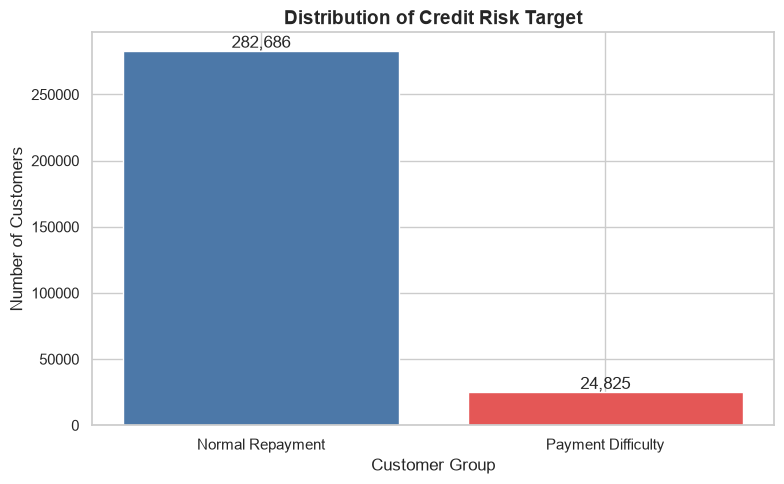

In [13]:

target_counts = (
    df_mart["TARGET"]
    .value_counts()
    .reindex([0, 1])
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Normal Repayment", "Payment Difficulty"],
    target_counts.values,
    color=["#4C78A8", "#E45756"]
)

for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{height:,.0f}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

ax.set_title(
    "Distribution of Credit Risk Target",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Number of Customers")
ax.set_xlabel("Customer Group")

plt.tight_layout()
plt.show()



### 4.2 Overall Credit Risk Distribution

전체 307,511명의 대출 신청 고객 중 상환 곤란 고객 비율은 약 8.07%이다.

이는 정상 상환 그룹이 대다수를 차지하는 불균형 데이터 구조임을 보여준다.

#### Business Implications

금융기관은 전체 고객 중 상대적으로 적은 비중을 차지하는 위험 고객을 효과적으로 식별해야 한다.

그러나 위험 고객의 탐지율만 높이는 정책은 정상 고객의 대출 기회까지 제한할 수 있다.

따라서 향후 모델링에서는 위험 고객 식별 능력과 함께 대출 승인율 및 잠재적인 신용손실을 분석한다.


In [14]:

# 분석용 데이터 복사
df_eda = df_mart.copy()

# 소득 0 이하 값 제외 (원본 데이터는 유지)
df_eda["INCOME_VALID"] = df_eda[
    "AMT_INCOME_TOTAL"
].where(df_eda["AMT_INCOME_TOTAL"] > 0)

# 소득 분위 구간 생성
df_eda["INCOME_GROUP"] = pd.qcut(
    df_eda["INCOME_VALID"],
    q=5,
    labels=[
        "Q1 (Lowest)",
        "Q2",
        "Q3",
        "Q4",
        "Q5 (Highest)"
    ],
    duplicates="drop"
)

income_risk = (
    df_eda.groupby(
        "INCOME_GROUP",
        observed=True
    )
    .agg(
        Customers=("TARGET", "size"),
        Bad_Rate=("TARGET", "mean"),
        Avg_Income=("AMT_INCOME_TOTAL", "mean")
    )
    .reset_index()
)

income_risk["Bad_Rate"] *= 100

display(income_risk)


,INCOME_GROUP,Customers,Bad_Rate,Avg_Income
0,Q1 (Lowest),63671,8.21,"78,064.97"
1,Q2,85756,8.59,"123,021.59"
2,Q3,35453,8.68,"155,407.43"
3,Q4,75513,8.06,"198,635.73"
4,Q5 (Highest),47118,6.52,"336,976.61"


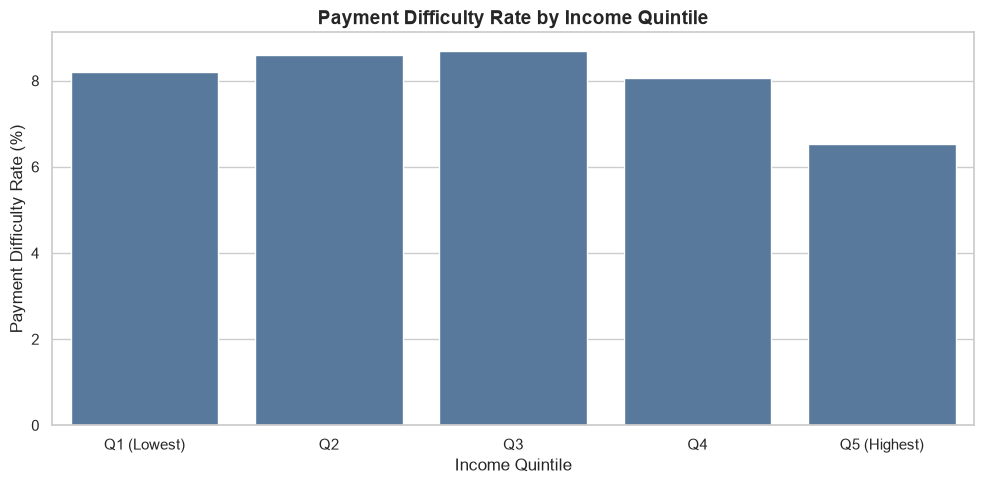

In [15]:

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=income_risk,
    x="INCOME_GROUP",
    y="Bad_Rate",
    color="#4C78A8",
    ax=ax
)

ax.set_title(
    "Payment Difficulty Rate by Income Quintile",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Income Quintile")
ax.set_ylabel("Payment Difficulty Rate (%)")

plt.tight_layout()
plt.show()



### 4.3 Income Level vs. Credit Risk

본 분석에서는 고객을 연소득 기준 5개 분위로 구분하여 상환 곤란 비율을 비교한다.

단순한 평균 소득 비교 대신 소득 구간별 위험률을 계산함으로써 고객의 경제적 특성과 신용위험 간 관계를 탐색한다.

#### Analytical Considerations

- 소득이 낮은 고객 집단의 위험률이 상대적으로 높은지 확인한다.
- 중간 소득 및 고소득 고객의 위험률 차이를 비교한다.
- 각 소득 구간의 고객 수를 함께 고려한다.

#### Business Implication

소득 수준이 신용위험과 관련되어 있더라도 단독 승인 기준으로 활용하기보다는 기존 부채, 대출 상환 부담 및 신용 이력과 함께 평가해야 한다.

실제 구간별 위험률과 증감 방향은 분석 결과를 바탕으로 판단한다.


In [17]:

df_eda["LOAN_TO_INCOME"] = (
    df_eda["AMT_CREDIT"]
    / df_eda["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

# 비율이 비정상적으로 큰 경우 확인
display(
    df_eda["LOAN_TO_INCOME"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]
    )
)


count   307,511.00
mean          3.96
std           2.69
min           0.00
25%           2.02
50%           3.27
75%           5.16
95%           9.16
99%          13.03
max          84.74
Name: LOAN_TO_INCOME, dtype: float64

In [18]:

bins = [0, 1, 2, 3, 5, np.inf]

labels = [
    "< 1x Income",
    "1–2x Income",
    "2–3x Income",
    "3–5x Income",
    "5x+ Income"
]

df_eda["LTI_GROUP"] = pd.cut(
    df_eda["LOAN_TO_INCOME"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

lti_risk = (
    df_eda.groupby(
        "LTI_GROUP",
        observed=True
    )
    .agg(
        Customers=("TARGET", "size"),
        Bad_Rate=("TARGET", "mean"),
        Avg_LTI=("LOAN_TO_INCOME", "mean")
    )
    .reset_index()
)

lti_risk["Bad_Rate"] *= 100

display(lti_risk)


,LTI_GROUP,Customers,Bad_Rate,Avg_LTI
0,< 1x Income,16174,6.44,0.77
1,1–2x Income,60164,7.70,1.57
2,2–3x Income,64858,8.69,2.53
3,3–5x Income,85508,8.84,3.94
4,5x+ Income,80807,7.38,7.54


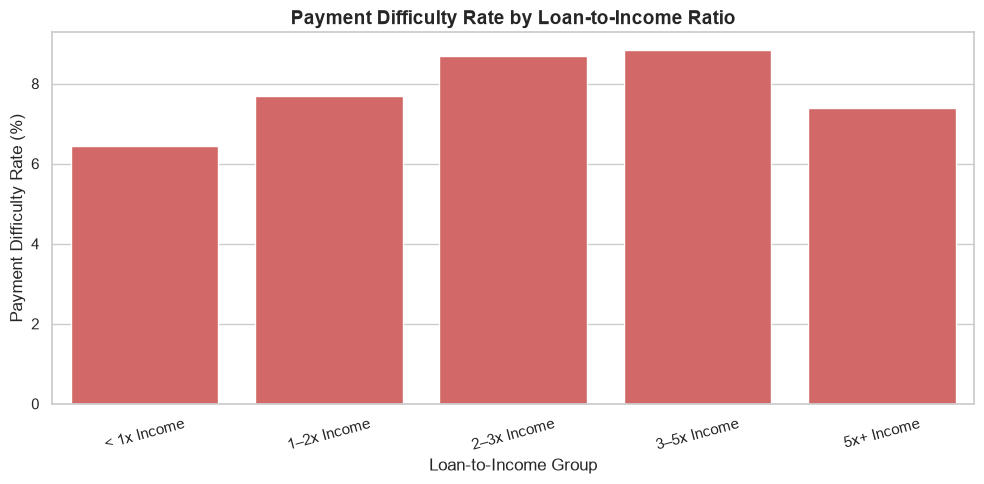

In [19]:

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=lti_risk,
    x="LTI_GROUP",
    y="Bad_Rate",
    color="#E45756",
    ax=ax
)

ax.set_title(
    "Payment Difficulty Rate by Loan-to-Income Ratio",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Loan-to-Income Group")
ax.set_ylabel("Payment Difficulty Rate (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()



### 4.4 Loan-to-Income Ratio vs. Credit Risk

Loan-to-Income Ratio는 신청 대출금액을 고객의 연소득으로 나눈 지표이다.

본 분석에서는 소득 대비 대출 규모에 따라 고객을 구간화하고 각 그룹의 상환 곤란 비율을 비교한다.

#### Business Questions

- 대출금액이 소득 대비 큰 고객에게 위험이 집중되는가?
- 위험률이 증가하거나 감소하는 특정 구간이 존재하는가?
- 대출 규모에 따른 위험 차이가 선형적으로 나타나는가?

#### Business Implication

Loan-to-Income Ratio는 대출 신청 규모와 고객의 소득 수준을 함께 반영하는 지표이다.

그러나 대출 만기, 금리, 기존 상환 의무 등을 직접 반영하지 않으므로 이 비율만으로 고객의 실제 상환 능력을 확정할 수 없다.

따라서 추가적인 부채 및 신용 이력 변수와 함께 분석할 필요가 있다.


In [21]:

df_eda["CREDIT_HISTORY_GROUP"] = pd.cut(
    df_eda["PAST_LOAN_COUNT"],
    bins=[-1, 0, 3, 10, 20, np.inf],
    labels=[
        "No History",
        "1–3 Records",
        "4–10 Records",
        "11–20 Records",
        "21+ Records"
    ]
)

history_risk = (
    df_eda.groupby(
        "CREDIT_HISTORY_GROUP",
        observed=True
    )
    .agg(
        Customers=("TARGET", "size"),
        Bad_Rate=("TARGET", "mean"),
        Avg_Records=("PAST_LOAN_COUNT", "mean")
    )
    .reset_index()
)

history_risk["Bad_Rate"] *= 100

display(history_risk)


,CREDIT_HISTORY_GROUP,Customers,Bad_Rate,Avg_Records
0,No History,44020,10.12,0.00
1,1–3 Records,104632,8.02,1.97
2,4–10 Records,126582,7.38,6.25
3,11–20 Records,29808,7.93,13.62
4,21+ Records,2469,11.18,24.94


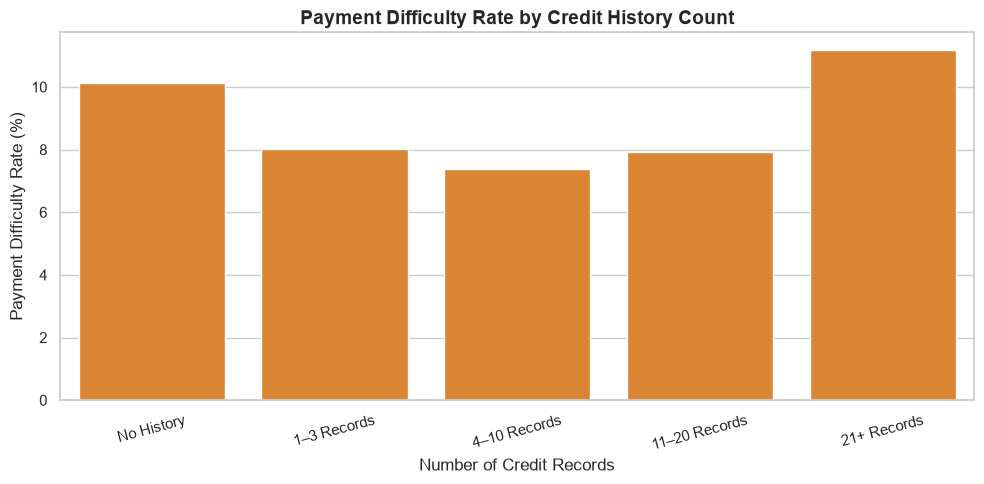

In [22]:

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=history_risk,
    x="CREDIT_HISTORY_GROUP",
    y="Bad_Rate",
    color="#F58518",
    ax=ax
)

ax.set_title(
    "Payment Difficulty Rate by Credit History Count",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Number of Credit Records")
ax.set_ylabel("Payment Difficulty Rate (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [23]:

# 소득 대비 보고된 기존 미상환 잔액
df_eda["DEBT_TO_INCOME_PROXY"] = (
    df_eda["ACTIVE_DEBT"]
    / df_eda["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

# 부채가 없는 고객과 부채가 있는 고객 구분
df_eda["DEBT_GROUP"] = np.where(
    df_eda["ACTIVE_DEBT"] > 0,
    "Reported Active Debt",
    "No Reported Active Debt"
)

debt_risk = (
    df_eda.groupby("DEBT_GROUP")
    .agg(
        Customers=("TARGET", "size"),
        Bad_Rate=("TARGET", "mean"),
        Avg_Debt=("ACTIVE_DEBT", "mean")
    )
    .reset_index()
)

debt_risk["Bad_Rate"] *= 100

display(debt_risk)


,DEBT_GROUP,Customers,Bad_Rate,Avg_Debt
0,No Reported Active Debt,123748,7.28,-298.31
1,Reported Active Debt,183763,8.61,"904,304.07"


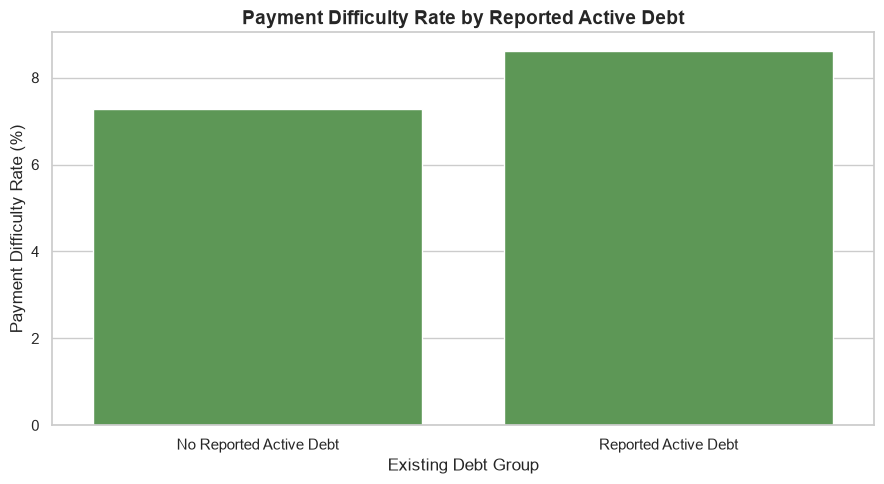

In [24]:

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=debt_risk,
    x="DEBT_GROUP",
    y="Bad_Rate",
    color="#54A24B",
    ax=ax
)

ax.set_title(
    "Payment Difficulty Rate by Reported Active Debt",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Existing Debt Group")
ax.set_ylabel("Payment Difficulty Rate (%)")

plt.tight_layout()
plt.show()



### 4.5 Credit History and Existing Debt Analysis

과거 신용 기록과 기존 미상환 부채는 고객의 재무적 부담을 이해하는 데 활용할 수 있는 정보이다.

본 분석에서는 다음 두 가지 관점으로 신용위험을 비교하였다.

**Credit History**
- 과거 신용 기록 건수에 따른 상환 곤란 비율
- 신용 이력이 없는 고객과 여러 신용 기록을 보유한 고객 비교

**Existing Debt**
- 보고된 활성 미상환 부채 보유 여부에 따른 위험률
- 소득 대비 기존 부채 규모를 나타내는 보조 지표 생성

#### Business Considerations

과거 신용 기록 개수나 기존 부채 보유 여부만으로 고객을 고위험으로 분류하는 것은 적절하지 않을 수 있다.

고객의 상환 능력, 소득 수준, 기존 연체 여부 및 다른 신용평가 변수를 함께 고려해야 한다.

또한 부채 관련 원천 데이터의 결측치가 0으로 대체된 경우, 실제 부채가 없는 고객과 부채 정보가 누락된 고객이 일부 혼재할 수 있다는 한계가 존재한다.


In [25]:

exposure_summary = (
    df_eda.groupby("TARGET")
    .agg(
        Customers=("SK_ID_CURR", "count"),
        Total_Requested_Credit=("AMT_CREDIT", "sum"),
        Avg_Requested_Credit=("AMT_CREDIT", "mean")
    )
    .reset_index()
)

exposure_summary["Customer_Share"] = (
    exposure_summary["Customers"]
    / exposure_summary["Customers"].sum()
    * 100
)

exposure_summary["Credit_Share"] = (
    exposure_summary["Total_Requested_Credit"]
    / exposure_summary["Total_Requested_Credit"].sum()
    * 100
)

exposure_summary["Customer_Group"] = (
    exposure_summary["TARGET"].map({
        0: "Normal Repayment",
        1: "Payment Difficulty"
    })
)

display(exposure_summary)


,TARGET,Customers,Total_Requested_Credit,Avg_Requested_Credit,Customer_Share,Credit_Share,Customer_Group
0,0,282686,"170,360,232,246.00","602,648.28",91.93,92.48,Normal Repayment
1,1,24825,"13,846,851,949.50","557,778.53",8.07,7.52,Payment Difficulty


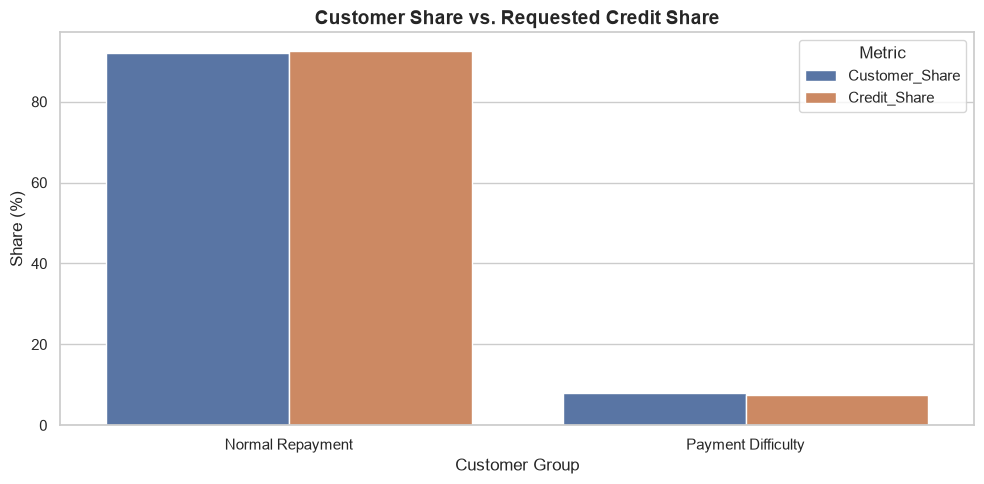

In [26]:

exposure_plot = exposure_summary.melt(
    id_vars="Customer_Group",
    value_vars=["Customer_Share", "Credit_Share"],
    var_name="Metric",
    value_name="Percentage"
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=exposure_plot,
    x="Customer_Group",
    y="Percentage",
    hue="Metric",
    ax=ax
)

ax.set_title(
    "Customer Share vs. Requested Credit Share",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Customer Group")
ax.set_ylabel("Share (%)")

plt.tight_layout()
plt.show()


In [27]:

print("=" * 55)
print("CREDIT RISK EDA — BUSINESS SUMMARY")
print("=" * 55)

print(f"\nOverall Bad Rate: {bad_rate:.2f}%")

print("\n[1] Income Risk")
display(income_risk)

print("\n[2] Loan-to-Income Risk")
display(lti_risk)

print("\n[3] Credit History Risk")
display(history_risk)

print("\n[4] Existing Debt Risk")
display(debt_risk)

print("\n[5] Credit Exposure")
display(exposure_summary)


CREDIT RISK EDA — BUSINESS SUMMARY

Overall Bad Rate: 8.07%

[1] Income Risk


,INCOME_GROUP,Customers,Bad_Rate,Avg_Income
0,Q1 (Lowest),63671,8.21,"78,064.97"
1,Q2,85756,8.59,"123,021.59"
2,Q3,35453,8.68,"155,407.43"
3,Q4,75513,8.06,"198,635.73"
4,Q5 (Highest),47118,6.52,"336,976.61"



[2] Loan-to-Income Risk


,LTI_GROUP,Customers,Bad_Rate,Avg_LTI
0,< 1x Income,16174,6.44,0.77
1,1–2x Income,60164,7.70,1.57
2,2–3x Income,64858,8.69,2.53
3,3–5x Income,85508,8.84,3.94
4,5x+ Income,80807,7.38,7.54



[3] Credit History Risk


,CREDIT_HISTORY_GROUP,Customers,Bad_Rate,Avg_Records
0,No History,44020,10.12,0.00
1,1–3 Records,104632,8.02,1.97
2,4–10 Records,126582,7.38,6.25
3,11–20 Records,29808,7.93,13.62
4,21+ Records,2469,11.18,24.94



[4] Existing Debt Risk


,DEBT_GROUP,Customers,Bad_Rate,Avg_Debt
0,No Reported Active Debt,123748,7.28,-298.31
1,Reported Active Debt,183763,8.61,"904,304.07"



[5] Credit Exposure


,TARGET,Customers,Total_Requested_Credit,Avg_Requested_Credit,Customer_Share,Credit_Share,Customer_Group
0,0,282686,"170,360,232,246.00","602,648.28",91.93,92.48,Normal Repayment
1,1,24825,"13,846,851,949.50","557,778.53",8.07,7.52,Payment Difficulty



### 4.6 EDA Summary & Business Insights

본 단계에서는 고객의 소득, 대출 규모, 과거 신용 기록 및 기존 부채와 상환 곤란 발생률 간 관계를 분석하였다.

#### Analytical Framework

1. 고객 소득 분위별 위험률 비교
2. 소득 대비 대출금 비율 분석
3. 과거 신용 기록 개수별 위험 분석
4. 기존 부채 보유 여부별 위험 비교
5. 정상 및 상환 곤란 고객의 대출 신청금액 비중 분석

#### Business Implications

분석 결과는 고객의 신용위험을 평가할 때 단일 변수보다 복합적인 재무 정보와 과거 신용 이력을 고려해야 하는지 검토하는 근거로 활용할 수 있다.

또한 고객 수 기준 위험 분석과 금액 기준 위험 분석을 함께 수행하여 금융기관의 잠재적인 위험 노출을 다양한 관점에서 살펴보았다.

#### Limitations

- 관찰 데이터 기반의 연관성 분석으로 인과관계를 입증하지 않는다.
- 과거 신용정보의 결측치와 보고 범위에 따른 측정 한계가 존재한다.
- 대출 신청금액은 실제 승인금액 및 실현 손실과 다르다.
- 구간별 분석은 다른 고객 특성의 영향을 통제하지 않은 탐색적 결과이다.

#### Next Step

EDA 결과를 바탕으로 신용위험 예측에 활용할 변수를 선정하고, 데이터 누출을 방지하는 머신러닝 전처리 파이프라인을 구축한다.



## 5. Feature Engineering & Data Preprocessing

### 5.1 Business Objective

신용위험 예측 모델의 성능과 해석 가능성을 높이기 위해 고객의 재무 상태 및 과거 신용 이력을 반영한 파생 변수를 생성한다.

금융기관은 단순히 고객의 소득이 높거나 낮은지만 평가하지 않는다. 소득 대비 신청 대출금 규모, 연간 상환 부담, 기존 미상환 부채 및 과거 신용 이력 등을 함께 고려해야 한다.

본 단계에서는 이러한 금융적 특성을 정량화하여 머신러닝에 활용할 분석 데이터를 구축한다.

### Key Objectives

1. 소득 대비 대출금 및 상환 부담 관련 파생 변수 생성
2. 과거 신용 이력 및 기존 부채 관련 변수 활용
3. 비정상적 값과 결측치 처리 전략 수립
4. Train / Validation / Test 데이터 분리
5. Data Leakage를 방지하는 전처리 Pipeline 설계

### Expected Business Value

- 고객별 재무 부담을 반영한 신용위험 평가
- 해석 가능한 신용위험 설명 변수 확보
- 일관되고 재현 가능한 모델링 데이터 구축
- 실제 신규 고객에 적용 가능한 예측 프로세스 설계


In [28]:

import numpy as np
import pandas as pd

# 원본 Data Mart 보존
df_model = df_mart.copy()

# 1. 소득 대비 신청 대출금 비율
df_model["LOAN_TO_INCOME"] = (
    df_model["AMT_CREDIT"]
    / df_model["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

# 2. 소득 대비 연간 상환 부담
df_model["PAYMENT_TO_INCOME"] = (
    df_model["AMT_ANNUITY"]
    / df_model["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

# 3. 소득 대비 기존 미상환 부채
df_model["DEBT_TO_INCOME_PROXY"] = (
    df_model["ACTIVE_DEBT"]
    / df_model["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

# 4. 신청 대출금 대비 연간 상환액 관계
df_model["CREDIT_TO_ANNUITY"] = (
    df_model["AMT_CREDIT"]
    / df_model["AMT_ANNUITY"].replace(0, np.nan)
)

# 5. 고객 연령
df_model["AGE_YEARS"] = (
    -df_model["DAYS_BIRTH"] / 365.25
)

# 6. 근속 기간
df_model["EMPLOYMENT_YEARS"] = (
    -df_model["DAYS_EMPLOYED"] / 365.25
)

# Home Credit의 DAYS_EMPLOYED 특수값 처리
df_model.loc[
    df_model["DAYS_EMPLOYED"] == 365243,
    "EMPLOYMENT_YEARS"
] = np.nan

# 무한대 값은 결측치로 변환
df_model = df_model.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Financial Feature Engineering Completed!")

display(
    df_model[
        [
            "LOAN_TO_INCOME",
            "PAYMENT_TO_INCOME",
            "DEBT_TO_INCOME_PROXY",
            "CREDIT_TO_ANNUITY",
            "AGE_YEARS",
            "EMPLOYMENT_YEARS"
        ]
    ].head()
)


Financial Feature Engineering Completed!


,LOAN_TO_INCOME,PAYMENT_TO_INCOME,DEBT_TO_INCOME_PROXY,CREDIT_TO_ANNUITY,AGE_YEARS,EMPLOYMENT_YEARS
0,2.01,0.12,1.21,16.46,25.90,1.74
1,4.79,0.13,0.00,36.23,45.90,3.25
2,2.00,0.10,0.00,20.00,52.15,0.62
3,2.32,0.22,0.00,10.53,52.03,8.32
4,4.22,0.18,0.00,23.46,54.57,8.32



### 5.2 Feature Selection Strategy

본 프로젝트에서는 고객의 상환 능력, 부채 부담, 과거 신용 이력 및 외부 신용평가 정보를 중심으로 모델 입력 변수를 선정한다.

#### Feature Categories

**1. Financial Capacity**
- AMT_INCOME_TOTAL
- AMT_CREDIT
- AMT_ANNUITY
- LOAN_TO_INCOME
- PAYMENT_TO_INCOME
- CREDIT_TO_ANNUITY

**2. Existing Credit Exposure**
- ACTIVE_DEBT
- TOTAL_PAST_CREDIT
- DEBT_TO_INCOME_PROXY

**3. Credit History**
- PAST_LOAN_COUNT
- ACTIVE_LOAN_COUNT
- OVERDUE_LOAN_COUNT
- MAX_DAYS_CREDIT

**4. Customer Characteristics**
- AGE_YEARS
- EMPLOYMENT_YEARS

**5. External Risk Information**
- EXT_SOURCE_1
- EXT_SOURCE_2
- EXT_SOURCE_3

고객 고유 식별자(SK_ID_CURR)는 예측 변수에서 제외한다.

성별 등 민감한 개인 속성은 이번 모델의 승인 판단 변수로 사용하지 않는다. 다만 해당 변수들을 제외하는 것만으로 알고리즘 공정성이 보장되는 것은 아니며, 실제 금융기관 적용 시 별도의 공정성 및 규제 검토가 필요하다.

본 변수 목록은 초기 모델링을 위한 가설 기반 선정이며, 최종적인 예측력과 중요도는 검증 데이터를 활용해 평가한다.


In [29]:

feature_cols = [
    # Financial capacity
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "LOAN_TO_INCOME",
    "PAYMENT_TO_INCOME",
    "CREDIT_TO_ANNUITY",

    # Existing credit exposure
    "ACTIVE_DEBT",
    "TOTAL_PAST_CREDIT",
    "DEBT_TO_INCOME_PROXY",

    # Credit history
    "PAST_LOAN_COUNT",
    "ACTIVE_LOAN_COUNT",
    "OVERDUE_LOAN_COUNT",
    "MAX_DAYS_CREDIT",

    # Customer characteristics
    "AGE_YEARS",
    "EMPLOYMENT_YEARS",

    # External risk information
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

# 변수 존재 여부 확인
missing_cols = [
    col for col in feature_cols
    if col not in df_model.columns
]

assert not missing_cols, f"Missing Columns: {missing_cols}"

X = df_model[feature_cols].copy()
y = df_model["TARGET"].copy()

assert X.index.equals(y.index)
assert y.notna().all()
assert y.isin([0, 1]).all()

print("Feature Matrix:", X.shape)
print("Target:", y.shape)
print("Number of Features:", len(feature_cols))

display(X.head())


Feature Matrix: (307511, 18)
Target: (307511,)
Number of Features: 18


,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,LOAN_TO_INCOME,PAYMENT_TO_INCOME,CREDIT_TO_ANNUITY,ACTIVE_DEBT,TOTAL_PAST_CREDIT,DEBT_TO_INCOME_PROXY,PAST_LOAN_COUNT,ACTIVE_LOAN_COUNT,OVERDUE_LOAN_COUNT,MAX_DAYS_CREDIT,AGE_YEARS,EMPLOYMENT_YEARS,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
0,"202,500.00","406,597.50","24,700.50",2.01,0.12,16.46,"245,781.00","865,055.56",1.21,8,2,0,-103.00,25.90,1.74,0.08,0.26,0.14
1,"270,000.00","1,293,502.50","35,698.50",4.79,0.13,36.23,0.00,"1,017,400.50",0.00,4,1,0,-606.00,45.90,3.25,0.31,0.62,NaN
2,"67,500.00","135,000.00","6,750.00",2.00,0.10,20.00,0.00,"189,037.80",0.00,2,0,0,-408.00,52.15,0.62,NaN,0.56,0.73
3,"135,000.00","312,682.50","29,686.50",2.32,0.22,10.53,0.00,0.00,0.00,0,0,0,NaN,52.03,8.32,NaN,0.65,NaN
4,"121,500.00","513,000.00","21,865.50",4.22,0.18,23.46,0.00,"146,250.00",0.00,1,0,0,"-1,149.00",54.57,8.32,NaN,0.32,NaN


In [30]:

missing_summary = pd.DataFrame({
    "Missing_Count": X.isna().sum(),
    "Missing_Rate": X.isna().mean() * 100
})

missing_summary = (
    missing_summary
    .sort_values("Missing_Rate", ascending=False)
)

display(missing_summary)


,Missing_Count,Missing_Rate
EXT_SOURCE_1,173378,56.38
EXT_SOURCE_3,60965,19.83
EMPLOYMENT_YEARS,55374,18.01
MAX_DAYS_CREDIT,44020,14.31
EXT_SOURCE_2,660,0.21
AMT_ANNUITY,12,0.00
PAYMENT_TO_INCOME,12,0.00
CREDIT_TO_ANNUITY,12,0.00
OVERDUE_LOAN_COUNT,0,0.00
AGE_YEARS,0,0.00


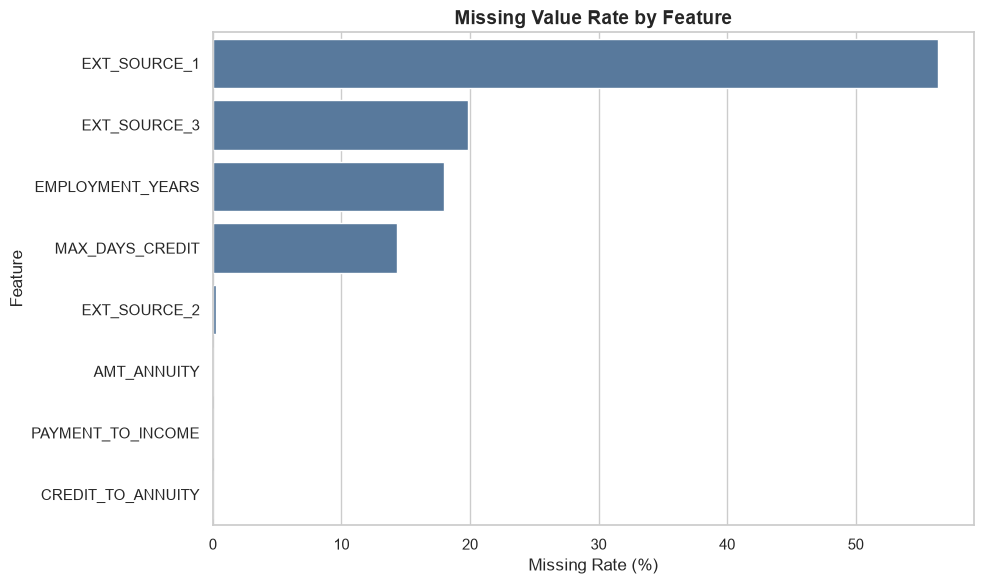

In [31]:

missing_plot = missing_summary[
    missing_summary["Missing_Rate"] > 0
]

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=missing_plot.reset_index(),
    x="Missing_Rate",
    y="index",
    color="#4C78A8",
    ax=ax
)

ax.set_title(
    "Missing Value Rate by Feature",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Missing Rate (%)")
ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()



### 5.3 Missing Value Analysis

금융 데이터에서는 고객별 정보 수집 범위가 다르기 때문에 결측치가 발생할 수 있다.

본 프로젝트에서는 변수별 결측률을 확인하고, 모델별 특성을 고려한 결측치 처리 전략을 적용한다.

#### Missing Value Treatment

- 수치형 변수는 학습 데이터에서 계산한 중앙값으로 대체한다.
- 결측치 대체에 필요한 통계량은 Train 데이터에서만 학습한다.
- Validation 및 Test 데이터에는 Train에서 학습한 동일한 전처리 규칙을 적용한다.

이 방식은 전체 데이터의 정보를 전처리 단계에서 미리 사용하는 Data Leakage를 방지하기 위한 것이다.

다만 결측치가 발생하는 이유 자체가 신용위험과 관련될 수 있으므로, 향후 결측 여부를 별도 변수로 추가하는 방안도 검토할 수 있다.



### 5.4 Train / Validation / Test Split

모델의 일반화 성능을 검증하기 위해 전체 데이터를 다음과 같이 분리한다.

- Training Set: 60%
- Validation Set: 20%
- Test Set: 20%

Training 데이터는 모델 학습에 사용한다.

Validation 데이터는 모델 비교, 하이퍼파라미터 조정 및 대출 승인 Threshold 선정에 활용한다.

Test 데이터는 최종적으로 선택된 모델과 정책을 평가하는 용도로 보존한다.

또한 상환 곤란 고객 비율이 약 8.07%로 불균형하기 때문에 Stratified Sampling을 적용하여 각 데이터셋에서 타깃 비율을 유사하게 유지한다.

본 데이터에는 전체 고객에 대한 일관된 신청 시점 정보가 제공되지 않으므로 무작위 분할을 활용한다. 실제 금융기관의 운영 환경에서는 시계열 기반 Out-of-Time Validation이 추가로 필요하다.


In [32]:

from sklearn.model_selection import train_test_split

# 60% Train / 40% Temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

# Temporary를 20% Validation / 20% Test로 분리
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nTarget Distribution")
print("Train:", round(y_train.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Test:", round(y_test.mean() * 100, 2), "%")


Train: (184506, 18)
Validation: (61502, 18)
Test: (61503, 18)

Target Distribution
Train: 8.07 %
Validation: 8.07 %
Test: 8.07 %


In [33]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Logistic Regression용 전처리
lr_preprocessor = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "scaler",
        StandardScaler()
    )
])

# LightGBM용 전처리
lgbm_preprocessor = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    )
])

print("Preprocessing Pipelines Created!")


Preprocessing Pipelines Created!


In [34]:

# 데이터 크기 검증
assert (
    len(X_train) + len(X_val) + len(X_test)
    == len(X)
)

# 분할 간 데이터 중복 확인
assert X_train.index.intersection(X_val.index).empty
assert X_train.index.intersection(X_test.index).empty
assert X_val.index.intersection(X_test.index).empty

# 타깃 검증
assert y_train.notna().all()
assert y_val.notna().all()
assert y_test.notna().all()

# 무한대 값 검증
for dataset in [X_train, X_val, X_test]:
    assert not np.isinf(dataset.to_numpy()).any()

print("All Preprocessing Validation Checks Passed!")
print("Ready for Machine Learning!")


All Preprocessing Validation Checks Passed!
Ready for Machine Learning!



### 5.5 Feature Engineering Summary

본 단계에서는 고객의 재무 상태, 기존 부채 및 신용 이력을 바탕으로 금융 비즈니스 관점의 파생 변수를 생성하였다.

#### Key Implementation

- Loan-to-Income Ratio 생성
- Payment-to-Income Ratio 생성
- Existing Debt-to-Income Proxy 생성
- 고객 연령 및 근속 기간 변수 생성
- 비정상적 근속 기간 값 및 무한대 처리
- 금융 및 신용 관련 주요 변수 선정
- 결측치 분석 및 중앙값 대체 전략 수립
- Stratified Train / Validation / Test 분리
- Data Leakage 방지를 위한 Scikit-learn Pipeline 설계

#### Business Implications

고객의 소득 수준뿐 아니라 신청 대출 규모, 상환 부담 및 과거 신용 이력을 함께 반영할 수 있는 분석 변수를 구축하였다.

이를 통해 단일 재무 변수에 의존하지 않고 고객의 신용위험을 종합적으로 평가할 수 있는 모델링 기반을 마련하였다.

#### Methodological Considerations

전처리 통계량은 Training 데이터에서만 학습하도록 설계하였다.

Validation 데이터는 모델 선택 및 의사결정 기준 설정에 활용하고, Test 데이터는 최종 성능 평가를 위해 분리하여 보존한다.

#### Next Step

Logistic Regression을 Baseline 모델로 학습하고, LightGBM과 예측 성능을 비교한다.

이후 ROC-AUC, PR-AUC 및 확률 보정 성능을 평가하여 대출 승인 정책 분석에 사용할 모델을 선정한다.



## 6. Predictive Modeling

### 6.1 Business Objective

본 단계에서는 고객의 재무 정보와 과거 신용 이력을 활용하여 상환 곤란 가능성을 예측하는 머신러닝 모델을 구축한다.

금융기관의 신용위험 모델은 단순한 분류 정확도뿐 아니라 위험 고객을 구분하는 능력, 모델 해석 가능성 및 예측확률의 신뢰성을 함께 고려해야 한다.

따라서 다음 두 모델을 비교한다.

**1. Logistic Regression (Baseline)**

- 선형적인 관계를 기반으로 상환 곤란 위험 추정
- 모델 계수 및 Odds Ratio를 통한 변수 영향 해석
- 복잡한 모델의 성능을 비교하기 위한 기준 모델

**2. LightGBM (Advanced Model)**

- 고객 특성과 신용위험 사이의 비선형 관계 학습
- 변수 간 상호작용을 활용한 예측
- 대용량 정형 데이터에 적합한 Gradient Boosting 모델

### Evaluation Strategy

모델 비교는 Validation 데이터에서 수행한다.

- ROC-AUC: 정상 고객과 위험 고객의 구분 능력
- PR-AUC: 소수 위험 고객에 대한 식별 성능
- Brier Score: 예측확률의 정확성
- Recall / Precision: 위험 고객 탐지 성능

최종 Test 데이터는 모델 선택 및 Threshold 조정 과정에서 사용하지 않는다.

### Business Goal

고객별 상환 곤란 위험을 정량적으로 추정하여 이후 대출 승인 정책 및 예상 신용손실 시뮬레이션에 활용할 수 있는 모델을 선정한다.


In [35]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

from lightgbm import LGBMClassifier

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Modeling libraries imported!")


Modeling libraries imported!



### 6.2 Logistic Regression Baseline

Logistic Regression을 신용위험 예측의 Baseline 모델로 설정한다.

Logistic Regression은 입력 변수와 상환 곤란 발생의 Log-Odds 간 선형 관계를 가정한다.

본 프로젝트에서는 수치형 변수의 결측치를 학습 데이터 기준 중앙값으로 대체하고 StandardScaler를 적용한다.

또한 결측 여부를 나타내는 Indicator 변수를 추가하여 데이터 누락 자체가 위험 예측에 유용한 정보를 제공하는지 학습할 수 있도록 한다.

모델 학습과 전처리를 하나의 Pipeline으로 결합하여 Validation 데이터의 정보가 학습 과정에 유입되지 않도록 한다.


In [36]:

# Logistic Regression Pipeline
lr_pipeline = Pipeline([
    ("preprocessor", lr_preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# 모델 학습
lr_pipeline.fit(X_train, y_train)

# Validation 예측확률
lr_val_proba = lr_pipeline.predict_proba(X_val)[:, 1]

print("Logistic Regression Training Completed!")


Logistic Regression Training Completed!


In [37]:

lr_roc_auc = roc_auc_score(
    y_val,
    lr_val_proba
)

lr_pr_auc = average_precision_score(
    y_val,
    lr_val_proba
)

lr_brier = brier_score_loss(
    y_val,
    lr_val_proba
)

print("=== Logistic Regression ===")
print(f"ROC-AUC:     {lr_roc_auc:.4f}")
print(f"PR-AUC:      {lr_pr_auc:.4f}")
print(f"Brier Score: {lr_brier:.4f}")


=== Logistic Regression ===
ROC-AUC:     0.7327
PR-AUC:      0.2150
Brier Score: 0.0692



### 6.3 LightGBM Model

LightGBM은 Gradient Boosting Decision Tree 기반 모델로, 정형 데이터의 비선형 패턴과 변수 간 상호작용을 학습할 수 있다.

본 프로젝트에서는 Logistic Regression과 동일한 학습 데이터를 사용하여 모델 간 예측 성능을 비교한다.

#### Modeling Strategy

- 동일한 Train / Validation 분할 사용
- 전처리 Pipeline을 통한 데이터 누출 방지
- ROC-AUC 및 PR-AUC 기반 분류 성능 평가
- Brier Score와 Calibration Curve를 통한 확률 예측 평가

LightGBM은 트리 기반 모델이므로 별도의 StandardScaler를 적용하지 않는다.

모델 선택 이후에는 예측확률 보정 및 금융 비즈니스 관점의 승인 Threshold 분석을 수행한다.


In [38]:

lgbm_pipeline = Pipeline([
    ("preprocessor", lgbm_preprocessor),
    ("model", LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    ))
])

# 모델 학습
lgbm_pipeline.fit(X_train, y_train)

# Validation 예측확률
lgbm_val_proba = lgbm_pipeline.predict_proba(X_val)[:, 1]

print("LightGBM Training Completed!")


LightGBM Training Completed!


In [39]:

lgbm_roc_auc = roc_auc_score(
    y_val,
    lgbm_val_proba
)

lgbm_pr_auc = average_precision_score(
    y_val,
    lgbm_val_proba
)

lgbm_brier = brier_score_loss(
    y_val,
    lgbm_val_proba
)

print("=== LightGBM ===")
print(f"ROC-AUC:     {lgbm_roc_auc:.4f}")
print(f"PR-AUC:      {lgbm_pr_auc:.4f}")
print(f"Brier Score: {lgbm_brier:.4f}")


=== LightGBM ===
ROC-AUC:     0.7573
PR-AUC:      0.2475
Brier Score: 0.0677


In [40]:

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "LightGBM"
    ],
    "ROC_AUC": [
        lr_roc_auc,
        lgbm_roc_auc
    ],
    "PR_AUC": [
        lr_pr_auc,
        lgbm_pr_auc
    ],
    "Brier_Score": [
        lr_brier,
        lgbm_brier
    ]
})

model_comparison = model_comparison.sort_values(
    "ROC_AUC",
    ascending=False
).reset_index(drop=True)

display(model_comparison.round(4))


,Model,ROC_AUC,PR_AUC,Brier_Score
0,LightGBM,0.76,0.25,0.07
1,Logistic Regression,0.73,0.21,0.07


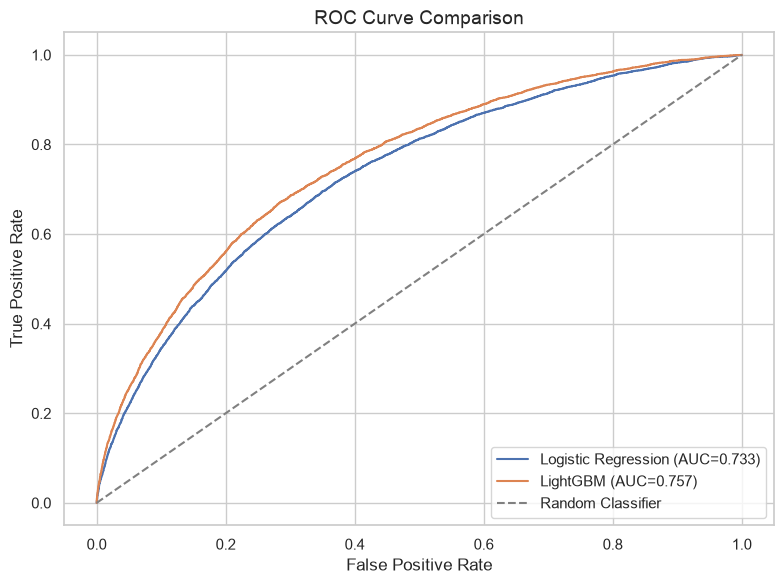

In [41]:

fig, ax = plt.subplots(figsize=(8, 6))

models = {
    "Logistic Regression": lr_val_proba,
    "LightGBM": lgbm_val_proba
}

for name, proba in models.items():

    fpr, tpr, _ = roc_curve(
        y_val,
        proba
    )

    auc = roc_auc_score(
        y_val,
        proba
    )

    ax.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

ax.set_title("ROC Curve Comparison", fontsize=14)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()


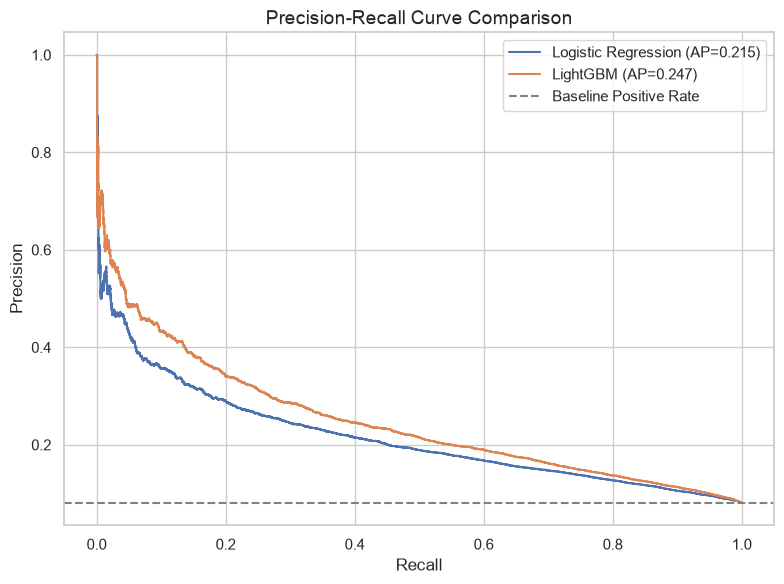

In [42]:

fig, ax = plt.subplots(figsize=(8, 6))

for name, proba in models.items():

    precision, recall, _ = precision_recall_curve(
        y_val,
        proba
    )

    ap = average_precision_score(
        y_val,
        proba
    )

    ax.plot(
        recall,
        precision,
        label=f"{name} (AP={ap:.3f})"
    )

ax.axhline(
    y_val.mean(),
    linestyle="--",
    color="gray",
    label="Baseline Positive Rate"
)

ax.set_title(
    "Precision-Recall Curve Comparison",
    fontsize=14
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()

plt.tight_layout()
plt.show()



### 6.4 Probability Calibration

신용위험 예측 모델은 위험 고객의 순위를 구분하는 능력뿐 아니라 예측확률의 신뢰성도 중요하다.

특히 금융기관에서 예상 신용손실을 계산하기 위해서는 예측확률이 실제 발생률과 유사한 수준으로 보정되어 있어야 한다.

본 프로젝트에서는 Calibration Curve와 Brier Score를 활용하여 모델의 확률 예측 성능을 평가한다.

- ROC-AUC: 위험 순위 구분 능력
- PR-AUC: 위험 고객 식별 성능
- Brier Score: 확률 예측 오차
- Calibration Curve: 예측 위험확률과 실제 발생률의 관계

예측확률의 보정 수준이 충분하지 않다면 별도의 Calibration 방법을 적용할 필요가 있다.


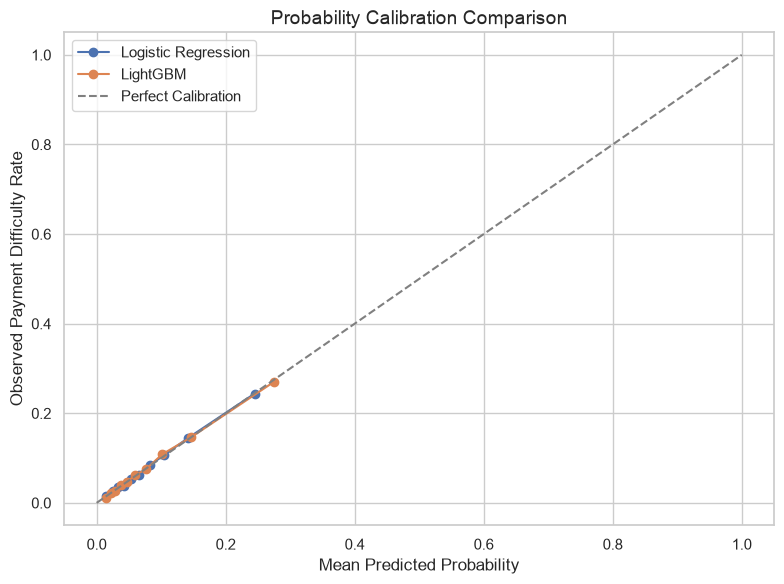

In [43]:

from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(8, 6))

for name, proba in models.items():

    prob_true, prob_pred = calibration_curve(
        y_val,
        proba,
        n_bins=10,
        strategy="quantile"
    )

    ax.plot(
        prob_pred,
        prob_true,
        marker="o",
        label=name
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration"
)

ax.set_title(
    "Probability Calibration Comparison",
    fontsize=14
)

ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Payment Difficulty Rate")

ax.legend()

plt.tight_layout()
plt.show()


In [45]:

best_model_name = model_comparison.iloc[0]["Model"]

if best_model_name == "LightGBM":
    best_pipeline = lgbm_pipeline
    best_val_proba = lgbm_val_proba
else:
    best_pipeline = lr_pipeline
    best_val_proba = lr_val_proba

print("Selected Candidate Model:", best_model_name)

print(
    "Validation ROC-AUC:",
    round(
        roc_auc_score(y_val, best_val_proba),
        4
    )
)

print(
    "Validation PR-AUC:",
    round(
        average_precision_score(y_val, best_val_proba),
        4
    )
)


Selected Candidate Model: LightGBM
Validation ROC-AUC: 0.7573
Validation PR-AUC: 0.2475


In [46]:

# 기본 Threshold 0.5
val_pred = (best_val_proba >= 0.5).astype(int)

print("=== Classification Report ===")

print(
    classification_report(
        y_val,
        val_pred,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix")

cm = confusion_matrix(
    y_val,
    val_pred
)

display(
    pd.DataFrame(
        cm,
        index=["Actual Normal", "Actual Difficulty"],
        columns=["Predicted Normal", "Predicted Difficulty"]
    )
)


=== Classification Report ===
              precision    recall  f1-score   support

           0     0.9206    0.9990    0.9582     56537
           1     0.6149    0.0183    0.0356      4965

    accuracy                         0.9198     61502
   macro avg     0.7677    0.5087    0.4969     61502
weighted avg     0.8959    0.9198    0.8837     61502


Confusion Matrix


,Predicted Normal,Predicted Difficulty
Actual Normal,56480,57
Actual Difficulty,4874,91


In [50]:

print("### 6.5 Model Evaluation Summary\n")

print(
    model_comparison.round(4).to_markdown(
        index=False
    )
)

print(f"\nSelected Candidate Model: **{best_model_name}**")

print(
    "\nThe candidate model was selected based on "
    "validation ROC-AUC. PR-AUC and calibration "
    "should also be considered before deployment."
)


### 6.5 Model Evaluation Summary

| Model               |   ROC_AUC |   PR_AUC |   Brier_Score |
|:--------------------|----------:|---------:|--------------:|
| LightGBM            |    0.7573 |   0.2475 |        0.0677 |
| Logistic Regression |    0.7327 |   0.215  |        0.0692 |

Selected Candidate Model: **LightGBM**

The candidate model was selected based on validation ROC-AUC. PR-AUC and calibration should also be considered before deployment.



## 6. Predictive Modeling

### 6.1 Business Objective

본 단계에서는 고객의 재무 정보와 과거 신용 이력을 활용하여 상환 곤란 가능성을 예측하는 머신러닝 모델을 구축한다.

금융기관의 신용위험 모델은 단순한 분류 정확도뿐 아니라 위험 고객을 구분하는 능력, 모델 해석 가능성 및 예측확률의 신뢰성을 함께 고려해야 한다.

따라서 다음 두 모델을 비교한다.

**1. Logistic Regression (Baseline)**

- 선형적인 관계를 기반으로 상환 곤란 위험 추정
- 모델 계수 및 Odds Ratio를 통한 변수 영향 해석
- 복잡한 모델의 성능을 비교하기 위한 기준 모델

**2. LightGBM (Advanced Model)**

- 고객 특성과 신용위험 사이의 비선형 관계 학습
- 변수 간 상호작용을 활용한 예측
- 대용량 정형 데이터에 적합한 Gradient Boosting 모델

### Evaluation Strategy

모델 비교는 Validation 데이터에서 수행한다.

- ROC-AUC: 정상 고객과 위험 고객의 구분 능력
- PR-AUC: 소수 위험 고객에 대한 식별 성능
- Brier Score: 예측확률의 정확성
- Recall / Precision: 위험 고객 탐지 성능

최종 Test 데이터는 모델 선택 및 Threshold 조정 과정에서 사용하지 않는다.

### Business Goal

고객별 상환 곤란 위험을 정량적으로 추정하여 이후 대출 승인 정책 및 예상 신용손실 시뮬레이션에 활용할 수 있는 모델을 선정한다.


In [51]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

from lightgbm import LGBMClassifier

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Modeling libraries imported!")


Modeling libraries imported!



### 6.2 Logistic Regression Baseline

Logistic Regression을 신용위험 예측의 Baseline 모델로 설정한다.

Logistic Regression은 입력 변수와 상환 곤란 발생의 Log-Odds 간 선형 관계를 가정한다.

본 프로젝트에서는 수치형 변수의 결측치를 학습 데이터 기준 중앙값으로 대체하고 StandardScaler를 적용한다.

또한 결측 여부를 나타내는 Indicator 변수를 추가하여 데이터 누락 자체가 위험 예측에 유용한 정보를 제공하는지 학습할 수 있도록 한다.

모델 학습과 전처리를 하나의 Pipeline으로 결합하여 Validation 데이터의 정보가 학습 과정에 유입되지 않도록 한다.


In [52]:

# Logistic Regression Pipeline
lr_pipeline = Pipeline([
    ("preprocessor", lr_preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# 모델 학습
lr_pipeline.fit(X_train, y_train)

# Validation 예측확률
lr_val_proba = lr_pipeline.predict_proba(X_val)[:, 1]

print("Logistic Regression Training Completed!")


Logistic Regression Training Completed!


In [53]:

lr_roc_auc = roc_auc_score(
    y_val,
    lr_val_proba
)

lr_pr_auc = average_precision_score(
    y_val,
    lr_val_proba
)

lr_brier = brier_score_loss(
    y_val,
    lr_val_proba
)

print("=== Logistic Regression ===")
print(f"ROC-AUC:     {lr_roc_auc:.4f}")
print(f"PR-AUC:      {lr_pr_auc:.4f}")
print(f"Brier Score: {lr_brier:.4f}")


=== Logistic Regression ===
ROC-AUC:     0.7327
PR-AUC:      0.2150
Brier Score: 0.0692



### 6.3 LightGBM Model

LightGBM은 Gradient Boosting Decision Tree 기반 모델로, 정형 데이터의 비선형 패턴과 변수 간 상호작용을 학습할 수 있다.

본 프로젝트에서는 Logistic Regression과 동일한 학습 데이터를 사용하여 모델 간 예측 성능을 비교한다.

#### Modeling Strategy

- 동일한 Train / Validation 분할 사용
- 전처리 Pipeline을 통한 데이터 누출 방지
- ROC-AUC 및 PR-AUC 기반 분류 성능 평가
- Brier Score와 Calibration Curve를 통한 확률 예측 평가

LightGBM은 트리 기반 모델이므로 별도의 StandardScaler를 적용하지 않는다.

모델 선택 이후에는 예측확률 보정 및 금융 비즈니스 관점의 승인 Threshold 분석을 수행한다.


In [54]:

lgbm_pipeline = Pipeline([
    ("preprocessor", lgbm_preprocessor),
    ("model", LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    ))
])

# 모델 학습
lgbm_pipeline.fit(X_train, y_train)

# Validation 예측확률
lgbm_val_proba = lgbm_pipeline.predict_proba(X_val)[:, 1]

print("LightGBM Training Completed!")


LightGBM Training Completed!


In [55]:

lgbm_roc_auc = roc_auc_score(
    y_val,
    lgbm_val_proba
)

lgbm_pr_auc = average_precision_score(
    y_val,
    lgbm_val_proba
)

lgbm_brier = brier_score_loss(
    y_val,
    lgbm_val_proba
)

print("=== LightGBM ===")
print(f"ROC-AUC:     {lgbm_roc_auc:.4f}")
print(f"PR-AUC:      {lgbm_pr_auc:.4f}")
print(f"Brier Score: {lgbm_brier:.4f}")


=== LightGBM ===
ROC-AUC:     0.7573
PR-AUC:      0.2475
Brier Score: 0.0677


In [56]:

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "LightGBM"
    ],
    "ROC_AUC": [
        lr_roc_auc,
        lgbm_roc_auc
    ],
    "PR_AUC": [
        lr_pr_auc,
        lgbm_pr_auc
    ],
    "Brier_Score": [
        lr_brier,
        lgbm_brier
    ]
})

model_comparison = model_comparison.sort_values(
    "ROC_AUC",
    ascending=False
).reset_index(drop=True)

display(model_comparison.round(4))


,Model,ROC_AUC,PR_AUC,Brier_Score
0,LightGBM,0.76,0.25,0.07
1,Logistic Regression,0.73,0.21,0.07


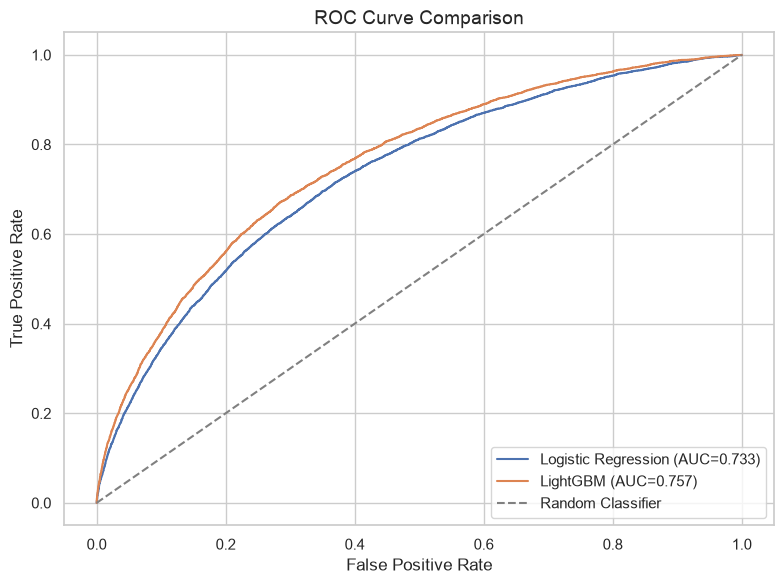

In [57]:

fig, ax = plt.subplots(figsize=(8, 6))

models = {
    "Logistic Regression": lr_val_proba,
    "LightGBM": lgbm_val_proba
}

for name, proba in models.items():

    fpr, tpr, _ = roc_curve(
        y_val,
        proba
    )

    auc = roc_auc_score(
        y_val,
        proba
    )

    ax.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

ax.set_title("ROC Curve Comparison", fontsize=14)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()


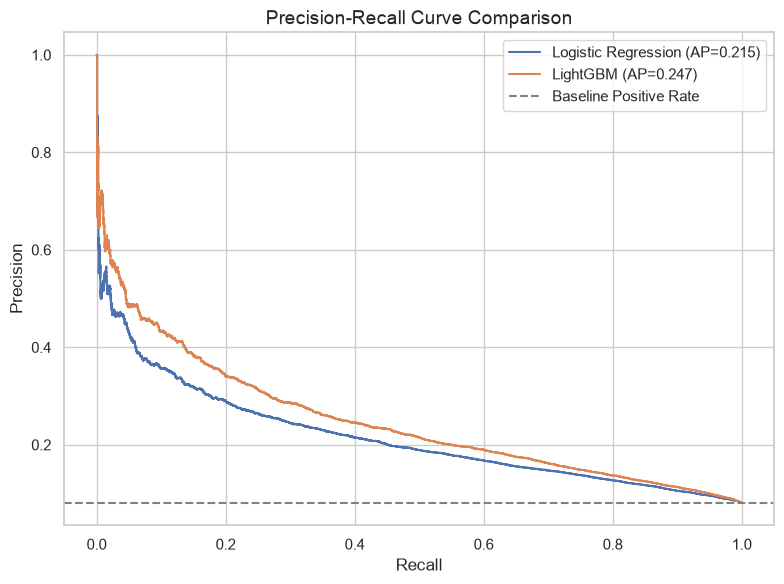

In [58]:

fig, ax = plt.subplots(figsize=(8, 6))

for name, proba in models.items():

    precision, recall, _ = precision_recall_curve(
        y_val,
        proba
    )

    ap = average_precision_score(
        y_val,
        proba
    )

    ax.plot(
        recall,
        precision,
        label=f"{name} (AP={ap:.3f})"
    )

ax.axhline(
    y_val.mean(),
    linestyle="--",
    color="gray",
    label="Baseline Positive Rate"
)

ax.set_title(
    "Precision-Recall Curve Comparison",
    fontsize=14
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()

plt.tight_layout()
plt.show()



### 6.4 Probability Calibration

신용위험 예측 모델은 위험 고객의 순위를 구분하는 능력뿐 아니라 예측확률의 신뢰성도 중요하다.

특히 금융기관에서 예상 신용손실을 계산하기 위해서는 예측확률이 실제 발생률과 유사한 수준으로 보정되어 있어야 한다.

본 프로젝트에서는 Calibration Curve와 Brier Score를 활용하여 모델의 확률 예측 성능을 평가한다.

- ROC-AUC: 위험 순위 구분 능력
- PR-AUC: 위험 고객 식별 성능
- Brier Score: 확률 예측 오차
- Calibration Curve: 예측 위험확률과 실제 발생률의 관계

예측확률의 보정 수준이 충분하지 않다면 별도의 Calibration 방법을 적용할 필요가 있다.


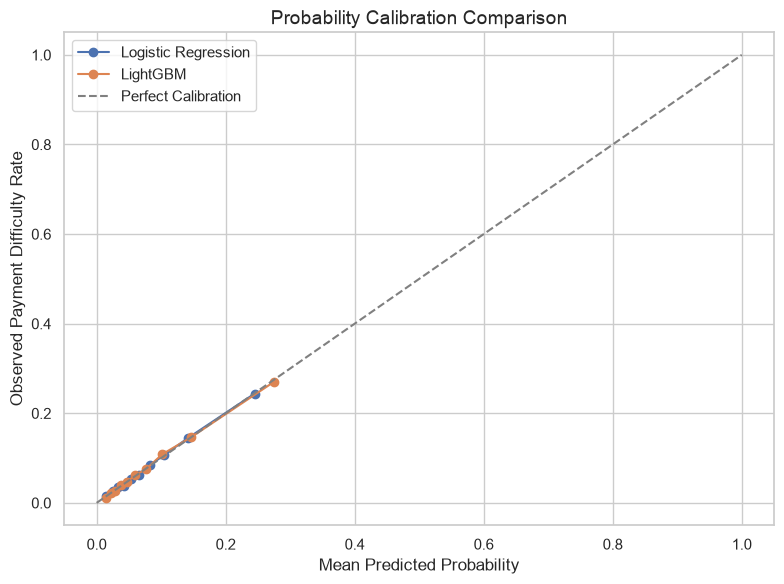

In [59]:

from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(8, 6))

for name, proba in models.items():

    prob_true, prob_pred = calibration_curve(
        y_val,
        proba,
        n_bins=10,
        strategy="quantile"
    )

    ax.plot(
        prob_pred,
        prob_true,
        marker="o",
        label=name
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration"
)

ax.set_title(
    "Probability Calibration Comparison",
    fontsize=14
)

ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Payment Difficulty Rate")

ax.legend()

plt.tight_layout()
plt.show()


In [60]:

best_model_name = model_comparison.iloc[0]["Model"]

if best_model_name == "LightGBM":
    best_pipeline = lgbm_pipeline
    best_val_proba = lgbm_val_proba
else:
    best_pipeline = lr_pipeline
    best_val_proba = lr_val_proba

print("Selected Candidate Model:", best_model_name)

print(
    "Validation ROC-AUC:",
    round(
        roc_auc_score(y_val, best_val_proba),
        4
    )
)

print(
    "Validation PR-AUC:",
    round(
        average_precision_score(y_val, best_val_proba),
        4
    )
)


Selected Candidate Model: LightGBM
Validation ROC-AUC: 0.7573
Validation PR-AUC: 0.2475


In [61]:

# 기본 Threshold 0.5
val_pred = (best_val_proba >= 0.5).astype(int)

print("=== Classification Report ===")

print(
    classification_report(
        y_val,
        val_pred,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix")

cm = confusion_matrix(
    y_val,
    val_pred
)

display(
    pd.DataFrame(
        cm,
        index=["Actual Normal", "Actual Difficulty"],
        columns=["Predicted Normal", "Predicted Difficulty"]
    )
)


=== Classification Report ===
              precision    recall  f1-score   support

           0     0.9206    0.9990    0.9582     56537
           1     0.6149    0.0183    0.0356      4965

    accuracy                         0.9198     61502
   macro avg     0.7677    0.5087    0.4969     61502
weighted avg     0.8959    0.9198    0.8837     61502


Confusion Matrix


,Predicted Normal,Predicted Difficulty
Actual Normal,56480,57
Actual Difficulty,4874,91


In [62]:

print("### 6.5 Model Evaluation Summary\n")

print(
    model_comparison.round(4).to_markdown(
        index=False
    )
)

print(f"\nSelected Candidate Model: **{best_model_name}**")

print(
    "\nThe candidate model was selected based on "
    "validation ROC-AUC. PR-AUC and calibration "
    "should also be considered before deployment."
)


### 6.5 Model Evaluation Summary

| Model               |   ROC_AUC |   PR_AUC |   Brier_Score |
|:--------------------|----------:|---------:|--------------:|
| LightGBM            |    0.7573 |   0.2475 |        0.0677 |
| Logistic Regression |    0.7327 |   0.215  |        0.0692 |

Selected Candidate Model: **LightGBM**

The candidate model was selected based on validation ROC-AUC. PR-AUC and calibration should also be considered before deployment.



### 6.5 Model Evaluation Summary

본 단계에서는 Logistic Regression과 LightGBM을 활용하여 고객의 상환 곤란 가능성을 예측하였다.

#### Model Comparison

모델 성능 비교 결과는 Validation 데이터에서 계산한 ROC-AUC, PR-AUC 및 Brier Score를 바탕으로 정리한다.

[여기에 Code 셀 ㊸에서 생성한 모델 비교표 삽입]

#### Key Findings

- Logistic Regression을 해석 가능한 Baseline 모델로 구축하였다.
- LightGBM을 활용해 비선형 관계를 학습하는 비교 모델을 구축하였다.
- ROC-AUC와 PR-AUC를 통해 위험 고객 구분 성능을 평가하였다.
- Brier Score 및 Calibration Curve를 통해 예측확률의 신뢰성을 검토하였다.

#### Business Implications

신용위험 예측 모델은 단순히 고객을 정상 또는 위험 고객으로 분류하는 데 그치지 않고, 고객별 위험확률을 활용해 대출 심사 기준을 비교하는 데 활용할 수 있다.

그러나 예측확률을 금융기관의 예상 손실 계산에 사용하기 위해서는 확률 보정과 데이터의 대표성을 추가로 검토해야 한다.

#### Limitations

- 공개 데이터 기반 모델이므로 실제 운영 환경과 차이가 존재할 수 있다.
- 무작위 데이터 분할은 시간에 따른 고객 특성 변화를 검증하지 못한다.
- 모델 예측확률은 실제 금융기관의 규제 목적 PD와 동일하지 않다.
- 모델별 성능 차이의 통계적 불확실성은 추가 검토가 필요하다.

#### Next Step

Validation 데이터를 활용하여 위험확률 Threshold에 따른 대출 승인율 및 상환 곤란 고객 차단율을 비교한다.

이후 확률 보정을 검토하고 가정 기반 예상 신용손실 시뮬레이션을 수행하여 금융기관의 대출 심사 전략을 제안한다.



## 7. Business-Oriented Model Evaluation & Threshold Optimization

### 7.1 Business Objective

신용위험 예측 모델의 목적은 단순히 고객의 상환 곤란 여부를 분류하는 것이 아니라, 금융기관의 대출 심사 의사결정을 지원하는 것이다.

금융기관은 대출 승인 과정에서 두 가지 비용을 고려해야 한다.

**1. Credit Risk Cost**
- 상환 곤란 고객에게 대출을 승인했을 때 발생할 수 있는 손실
- 위험 고객에 대한 과도한 신용 노출

**2. Opportunity Cost**
- 정상 상환 가능성이 높은 고객의 대출을 거절하면서 발생하는 수익 기회 손실
- 지나치게 보수적인 대출 심사 정책으로 인한 승인율 감소

따라서 본 프로젝트에서는 모델의 예측확률을 활용하여 다양한 대출 승인 기준을 시뮬레이션한다.

### Business Questions

1. 위험확률 기준에 따라 대출 승인율은 어떻게 달라지는가?
2. 승인 고객의 실제 상환 곤란 비율은 어떻게 변화하는가?
3. 상환 곤란 고객 중 얼마나 많은 고객을 차단할 수 있는가?
4. 위험 관리와 승인 기회 사이의 적절한 균형점은 어디인가?

### Policy Assumption

예측된 상환 곤란 확률이 Threshold 미만인 고객을 승인 후보로 분류한다.

이는 실제 금융기관의 승인 정책이 아닌 분석 목적의 가상 시뮬레이션이다.


In [63]:

import numpy as np
import pandas as pd

# Validation 예측확률
risk_scores = np.asarray(best_val_proba)

# 실제 상환 곤란 여부
actual = y_val.to_numpy()

# 신청 대출금액
credit_amount = X_val["AMT_CREDIT"].to_numpy()

# 정책별 Threshold
thresholds = np.arange(0.05, 0.51, 0.05)

policy_results = []

for threshold in thresholds:

    # 위험확률이 기준 미만이면 승인
    approved = risk_scores < threshold
    rejected = ~approved

    total_customers = len(actual)
    approved_count = approved.sum()

    # 전체 정상 / 위험 고객
    total_bad = (actual == 1).sum()
    total_good = (actual == 0).sum()

    # 승인 고객 중 실제 위험 고객
    approved_bad = (
        approved & (actual == 1)
    ).sum()

    # 거절된 위험 고객
    rejected_bad = (
        rejected & (actual == 1)
    ).sum()

    # 거절된 정상 고객
    rejected_good = (
        rejected & (actual == 0)
    ).sum()

    approval_rate = approved_count / total_customers

    approved_bad_rate = (
        approved_bad / approved_count
        if approved_count > 0 else np.nan
    )

    bad_capture_rate = rejected_bad / total_bad

    good_rejection_rate = rejected_good / total_good

    approval_amount_share = (
        credit_amount[approved].sum()
        / credit_amount.sum()
    )

    policy_results.append({
        "Threshold": round(threshold, 2),
        "Approved_Customers": approved_count,
        "Approval_Rate": approval_rate,
        "Approved_Bad_Rate": approved_bad_rate,
        "Bad_Capture_Rate": bad_capture_rate,
        "Good_Rejection_Rate": good_rejection_rate,
        "Approval_Amount_Share": approval_amount_share
    })

policy_df = pd.DataFrame(policy_results)

display(policy_df.round(4))


,Threshold,Approved_Customers,Approval_Rate,Approved_Bad_Rate,Bad_Capture_Rate,Good_Rejection_Rate,Approval_Amount_Share
0,0.05,29404,0.48,0.03,0.83,0.49,0.51
1,0.10,45982,0.75,0.04,0.60,0.22,0.77
2,0.15,52811,0.86,0.05,0.42,0.12,0.88
3,0.20,56348,0.92,0.06,0.30,0.07,0.93
4,0.25,58493,0.95,0.07,0.21,0.04,0.96
5,0.30,59687,0.97,0.07,0.14,0.02,0.98
6,0.35,60459,0.98,0.07,0.09,0.01,0.99
7,0.40,60900,0.99,0.08,0.06,0.01,0.99
8,0.45,61169,0.99,0.08,0.04,0.00,1.00
9,0.50,61354,1.00,0.08,0.02,0.00,1.00


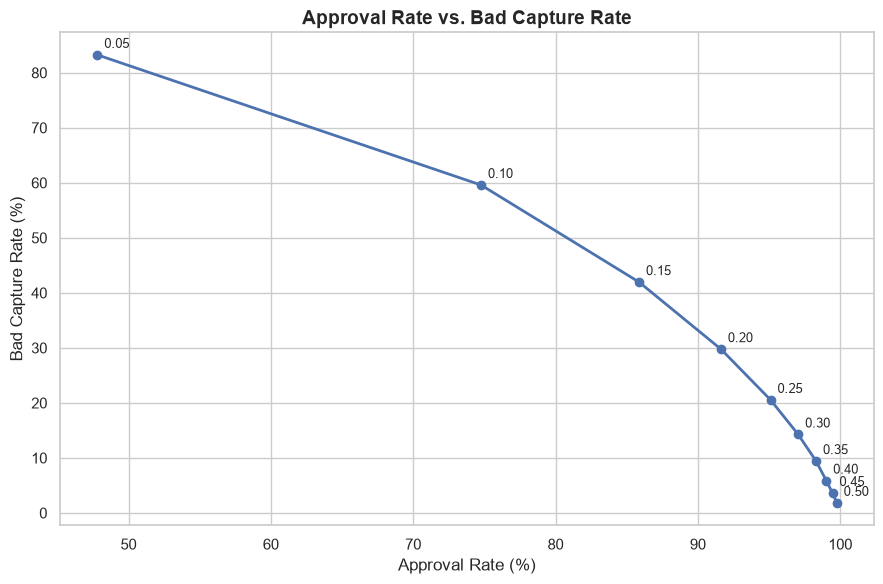

In [64]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    policy_df["Approval_Rate"] * 100,
    policy_df["Bad_Capture_Rate"] * 100,
    marker="o",
    linewidth=2
)

for _, row in policy_df.iterrows():
    ax.annotate(
        f"{row['Threshold']:.2f}",
        (
            row["Approval_Rate"] * 100,
            row["Bad_Capture_Rate"] * 100
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

ax.set_title(
    "Approval Rate vs. Bad Capture Rate",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Approval Rate (%)")
ax.set_ylabel("Bad Capture Rate (%)")

plt.tight_layout()
plt.show()



### 7.2 Approval Policy Trade-off

Threshold별 대출 승인 정책을 시뮬레이션하여 승인율과 위험 고객 차단율 간 관계를 분석하였다.

#### Key Considerations

- Threshold가 낮을수록 승인 기준이 엄격해진다.
- Threshold가 높을수록 더 많은 고객이 승인 대상에 포함된다.
- 승인율을 높이는 정책은 신용위험 노출을 증가시킬 수 있다.
- 지나치게 엄격한 기준은 정상 고객의 대출 기회를 제한할 수 있다.

#### Business Implication

금융기관은 위험 고객 차단율만을 극대화하기보다 정상 고객에 대한 승인 기회와 신용위험 수준을 함께 고려해야 한다.

따라서 최종 승인 정책은 모델 성능뿐 아니라 최소 승인율, 위험 허용 수준 및 예상 손실을 반영하여 선정할 필요가 있다.


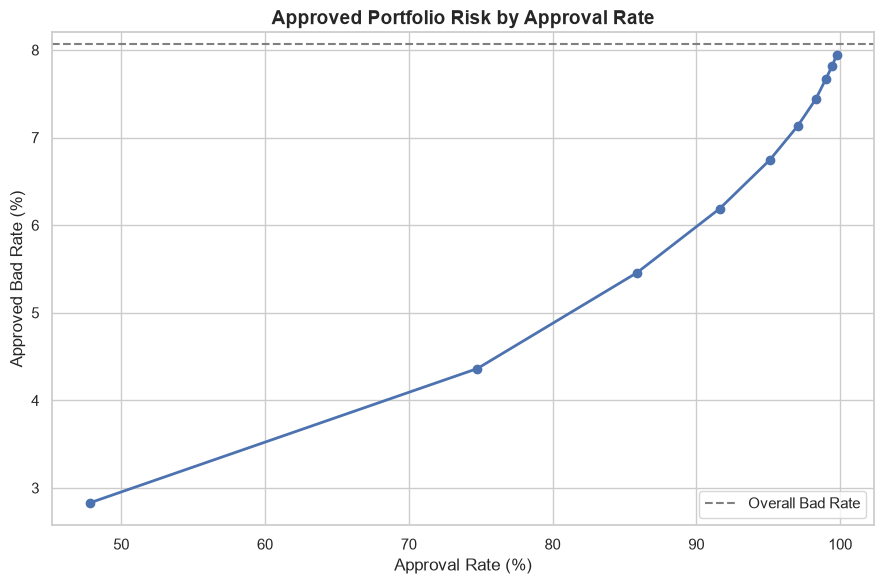

In [65]:

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    policy_df["Approval_Rate"] * 100,
    policy_df["Approved_Bad_Rate"] * 100,
    marker="o",
    linewidth=2
)

ax.axhline(
    y_val.mean() * 100,
    linestyle="--",
    color="gray",
    label="Overall Bad Rate"
)

ax.set_title(
    "Approved Portfolio Risk by Approval Rate",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Approval Rate (%)")
ax.set_ylabel("Approved Bad Rate (%)")
ax.legend()

plt.tight_layout()
plt.show()


In [66]:

risk_decile_df = pd.DataFrame({
    "Predicted_Risk": risk_scores,
    "Actual": actual
})

risk_decile_df["Risk_Decile"] = pd.qcut(
    risk_decile_df["Predicted_Risk"],
    q=10,
    labels=False,
    duplicates="drop"
) + 1

decile_summary = (
    risk_decile_df.groupby("Risk_Decile")
    .agg(
        Customers=("Actual", "size"),
        Avg_Predicted_Risk=("Predicted_Risk", "mean"),
        Actual_Bad_Rate=("Actual", "mean")
    )
    .reset_index()
)

display(decile_summary.round(4))


,Risk_Decile,Customers,Avg_Predicted_Risk,Actual_Bad_Rate
0,1,6151,0.01,0.01
1,2,6150,0.02,0.02
2,3,6150,0.03,0.03
3,4,6150,0.04,0.04
4,5,6150,0.05,0.05
5,6,6150,0.06,0.06
6,7,6150,0.08,0.07
7,8,6150,0.10,0.11
8,9,6150,0.15,0.15
9,10,6151,0.28,0.27


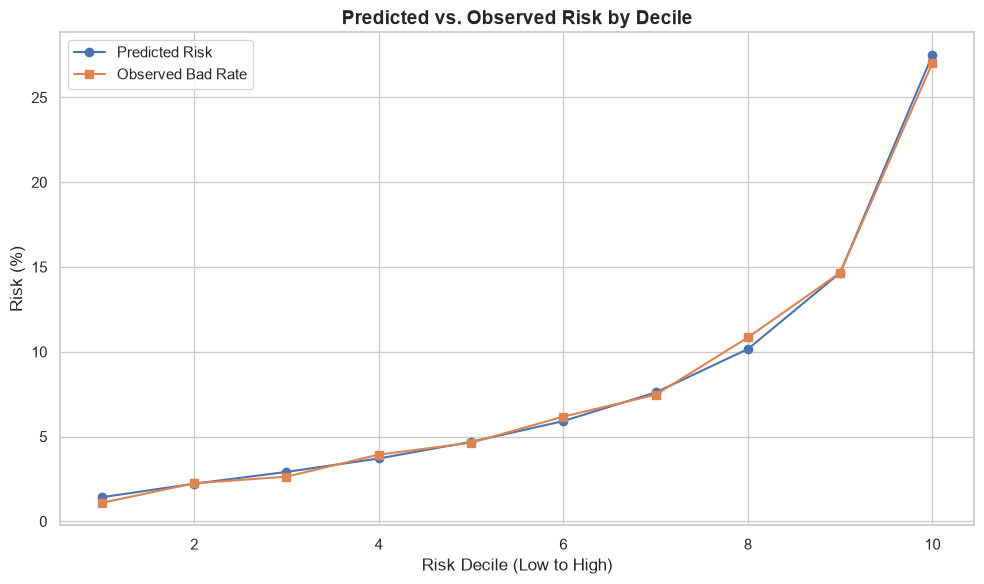

In [67]:

fig, ax = plt.subplots(figsize=(10, 6))

x = decile_summary["Risk_Decile"]

ax.plot(
    x,
    decile_summary["Avg_Predicted_Risk"] * 100,
    marker="o",
    label="Predicted Risk"
)

ax.plot(
    x,
    decile_summary["Actual_Bad_Rate"] * 100,
    marker="s",
    label="Observed Bad Rate"
)

ax.set_title(
    "Predicted vs. Observed Risk by Decile",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Risk Decile (Low to High)")
ax.set_ylabel("Risk (%)")
ax.legend()

plt.tight_layout()
plt.show()



### 7.3 Business-Constrained Threshold Optimization

금융기관은 단순히 위험확률이 낮은 고객만 승인하는 정책을 선택할 수 없다.

신용위험을 낮추는 동시에 일정 수준 이상의 대출 승인 기회를 유지해야 하기 때문이다.

본 프로젝트에서는 다음과 같은 가상의 비즈니스 제약조건을 설정한다.

**Policy Constraints**

- Minimum Approval Rate: 50%
- Maximum Approved Bad Rate: 5%

이 조건을 충족하는 정책 중 승인율이 가장 높은 Threshold를 선정한다.

이는 실제 금융기관의 승인 정책을 의미하지 않으며, 모델 기반 의사결정의 활용 가능성을 평가하기 위한 시뮬레이션이다.


In [68]:

MIN_APPROVAL_RATE = 0.50
MAX_APPROVED_BAD_RATE = 0.05

feasible_policies = policy_df[
    (policy_df["Approval_Rate"] >= MIN_APPROVAL_RATE)
    &
    (policy_df["Approved_Bad_Rate"] <= MAX_APPROVED_BAD_RATE)
].copy()

if feasible_policies.empty:

    selected_policy = None
    selected_threshold = None

    print("No feasible policy found.")
    print("Business constraints may need reconsideration.")

else:

    selected_policy = (
        feasible_policies
        .sort_values(
            "Approval_Rate",
            ascending=False
        )
        .iloc[0]
    )

    selected_threshold = float(
        selected_policy["Threshold"]
    )

    print("Selected Threshold:", selected_threshold)

    display(
        selected_policy.to_frame().T.round(4)
    )


Selected Threshold: 0.1


,Threshold,Approved_Customers,Approval_Rate,Approved_Bad_Rate,Bad_Capture_Rate,Good_Rejection_Rate,Approval_Amount_Share
1,0.10,"45,982.00",0.75,0.04,0.60,0.22,0.77


In [69]:

# 승인율 기준으로 시나리오 구성
target_approval_rates = {
    "Conservative": 0.30,
    "Balanced": 0.50,
    "Growth-Oriented": 0.70
}

scenario_rows = []

for strategy, target_rate in target_approval_rates.items():

    candidate = policy_df.iloc[
        (
            policy_df["Approval_Rate"] - target_rate
        ).abs().argsort()[:1]
    ]

    row = candidate.iloc[0].to_dict()
    row["Strategy"] = strategy
    row["Target_Approval_Rate"] = target_rate

    scenario_rows.append(row)

strategy_comparison = pd.DataFrame(scenario_rows)

display(
    strategy_comparison[
        [
            "Strategy",
            "Threshold",
            "Target_Approval_Rate",
            "Approval_Rate",
            "Approved_Bad_Rate",
            "Bad_Capture_Rate",
            "Good_Rejection_Rate"
        ]
    ].round(4)
)


,Strategy,Threshold,Target_Approval_Rate,Approval_Rate,Approved_Bad_Rate,Bad_Capture_Rate,Good_Rejection_Rate
0,Conservative,0.05,0.30,0.48,0.03,0.83,0.49
1,Balanced,0.05,0.50,0.48,0.03,0.83,0.49
2,Growth-Oriented,0.10,0.70,0.75,0.04,0.60,0.22



### 7.4 Business-Oriented Model Evaluation Summary

본 단계에서는 고객별 상환 곤란 예측확률을 활용하여 대출 승인 정책을 시뮬레이션하였다.

#### Key Analysis

1. Threshold별 대출 승인율 분석
2. 승인 고객의 상환 곤란 비율 평가
3. 위험 고객 차단율과 정상 고객 거절률 비교
4. Risk Decile을 통한 예측확률과 관측 위험률 비교
5. 비즈니스 제약조건 기반 승인 Threshold 검토

#### Business Implications

예측 모델을 활용하면 위험확률 수준에 따라 고객을 구분하고, 대출 승인율과 신용위험 사이의 Trade-off를 정량적으로 비교할 수 있다.

특히 금융기관이 최소 승인율과 최대 위험 허용 수준을 정의하면 해당 제약조건을 충족하는 정책 후보를 검토할 수 있다.

#### Limitations

- 실제 승인 여부가 아닌 가상 승인 정책에 기반한 분석이다.
- Validation 데이터에서 선택한 정책의 성능은 낙관적으로 평가될 가능성이 있다.
- 모델의 확률 보정 수준에 따라 위험확률 기반 정책 결과가 달라질 수 있다.
- 실제 대출 심사에는 규제, 공정성, 금리, 대출 만기, 담보 및 수익성 등을 추가로 고려해야 한다.

#### Next Step

위험확률과 신청 대출금액을 활용하여 가정 기반 예상 신용손실 시뮬레이션을 수행한다.

이를 통해 대출 승인율, 예상 신용손실 및 잠재적인 수익 기회 사이의 균형을 검토한다.



## 8. Expected Credit Loss & Risk-Adjusted Profit Simulation

### 8.1 Business Objective

신용위험 예측 모델의 비즈니스 가치를 평가하기 위해 대출 승인 정책별 예상 신용손실과 위험조정 수익을 시뮬레이션한다.

금융기관은 대출 승인율을 높여 수익 기회를 확보할 수 있지만, 동시에 신용위험에 따른 손실이 증가할 가능성이 있다.

따라서 본 프로젝트에서는 고객별 상환 곤란 예측확률과 신청 대출금액을 활용하여 다음 질문에 답하고자 한다.

1. 대출 승인 기준에 따라 예상 신용손실은 얼마나 달라지는가?
2. 승인율이 증가하면 예상 수익과 신용손실은 어떻게 변화하는가?
3. 금융기관이 설정한 위험 및 승인율 조건에서 어떤 정책이 가장 높은 위험조정 수익을 제공하는가?

### Financial Modeling Approach

- Probability of Default Proxy (PD): 모델의 상환 곤란 예측확률
- Loss Given Default (LGD): 부도 발생 시 손실률에 대한 가정
- Exposure at Default Proxy (EAD): 고객의 신청 대출금액
- Expected Credit Loss Proxy: PD × LGD × EAD
- Risk-Adjusted Profit Proxy: 예상 영업기여액 - 예상 신용손실

### Limitations

Home Credit 데이터는 실제 부도 발생 시 손실액, 계약별 금리, 조달비용 및 완전한 회계상 신용손실 정보를 제공하지 않는다.

따라서 본 분석은 실제 IFRS 9 ECL 또는 은행의 확정 수익을 추정하는 것이 아닌, 가정 기반 금융 시나리오 분석이다.


In [70]:

from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone
from sklearn.metrics import (
    brier_score_loss,
    roc_auc_score,
    average_precision_score
)

# 학습 데이터 내부에서 교차검증 기반 확률 보정
calibrated_model = CalibratedClassifierCV(
    estimator=clone(best_pipeline),
    method="sigmoid",
    cv=3,
    ensemble=False
)

calibrated_model.fit(X_train, y_train)

# Validation 데이터 예측
calibrated_val_proba = (
    calibrated_model.predict_proba(X_val)[:, 1]
)

calibration_comparison = pd.DataFrame({
    "Model": ["Original", "Calibrated"],
    "ROC_AUC": [
        roc_auc_score(y_val, best_val_proba),
        roc_auc_score(y_val, calibrated_val_proba)
    ],
    "PR_AUC": [
        average_precision_score(y_val, best_val_proba),
        average_precision_score(y_val, calibrated_val_proba)
    ],
    "Brier_Score": [
        brier_score_loss(y_val, best_val_proba),
        brier_score_loss(y_val, calibrated_val_proba)
    ]
})

display(calibration_comparison.round(5))


,Model,ROC_AUC,PR_AUC,Brier_Score
0,Original,0.76,0.25,0.07
1,Calibrated,0.76,0.25,0.07


In [71]:

original_brier = brier_score_loss(
    y_val, best_val_proba
)

calibrated_brier = brier_score_loss(
    y_val, calibrated_val_proba
)

if calibrated_brier < original_brier:
    financial_model = calibrated_model
    financial_val_proba = calibrated_val_proba
    probability_method = "Calibrated"
else:
    financial_model = best_pipeline
    financial_val_proba = best_val_proba
    probability_method = "Original"

print("Selected Probability Method:", probability_method)
print(
    "Validation Brier Score:",
    min(original_brier, calibrated_brier)
)


Selected Probability Method: Original
Validation Brier Score: 0.06771176471518607


In [72]:

# 가상 금융 시나리오 설정
LGD = 0.45
CONTRIBUTION_RATE = 0.08

MIN_APPROVAL_RATE = 0.50
MAX_APPROVED_BAD_RATE = 0.05

print("LGD:", LGD)
print("Contribution Rate:", CONTRIBUTION_RATE)
print("Minimum Approval Rate:", MIN_APPROVAL_RATE)
print("Maximum Approved Bad Rate:", MAX_APPROVED_BAD_RATE)


LGD: 0.45
Contribution Rate: 0.08
Minimum Approval Rate: 0.5
Maximum Approved Bad Rate: 0.05


In [73]:

risk_scores = np.asarray(financial_val_proba)
actual = y_val.to_numpy()

credit_amount = (
    X_val["AMT_CREDIT"]
    .to_numpy(dtype=float)
)

thresholds = np.linspace(0.01, 0.99, 99)

financial_results = []

for threshold in thresholds:

    approved = risk_scores < threshold

    approved_count = approved.sum()

    if approved_count == 0:
        continue

    approved_pd = risk_scores[approved]
    approved_credit = credit_amount[approved]

    approval_rate = approved_count / len(actual)

    approved_bad_rate = actual[approved].mean()

    # 예상 신용손실 대용 지표
    expected_loss = np.sum(
        approved_pd * LGD * approved_credit
    )

    # 정상 상환 시 영업기여액 가정
    expected_contribution = np.sum(
        (1 - approved_pd)
        * approved_credit
        * CONTRIBUTION_RATE
    )

    # 위험조정 수익 대용 지표
    risk_adjusted_profit = (
        expected_contribution - expected_loss
    )

    total_approved_amount = approved_credit.sum()

    financial_results.append({
        "Threshold": round(threshold, 4),
        "Approved_Customers": approved_count,
        "Approval_Rate": approval_rate,
        "Approved_Bad_Rate": approved_bad_rate,
        "Approved_Amount": total_approved_amount,
        "Expected_Contribution": expected_contribution,
        "Expected_Loss": expected_loss,
        "Risk_Adjusted_Profit": risk_adjusted_profit,
        "Profit_Margin": (
            risk_adjusted_profit / total_approved_amount
        )
    })

financial_df = pd.DataFrame(financial_results)

display(financial_df.round(4))


,Threshold,Approved_Customers,Approval_Rate,Approved_Bad_Rate,Approved_Amount,Expected_Contribution,Expected_Loss,Risk_Adjusted_Profit,Profit_Margin
0,0.01,766,0.01,0.01,"617,609,331.00","49,018,777.23","2,193,577.06","46,825,200.17",0.08
1,0.02,7242,0.12,0.01,"4,698,322,303.50","370,300,518.53","31,304,619.85","338,995,898.68",0.07
2,0.03,16106,0.26,0.02,"10,301,157,679.50","807,368,677.97","94,072,142.21","713,296,535.75",0.07
3,0.04,23573,0.38,0.02,"15,033,939,169.50","1,172,823,336.50","168,141,358.47","1,004,681,978.03",0.07
4,0.05,29404,0.48,0.03,"18,634,000,419.00","1,447,930,947.15","240,688,610.80","1,207,242,336.35",0.06
...,...,...,...,...,...,...,...,...,...
94,0.95,61502,1.00,0.08,"36,753,744,528.00","2,718,242,463.97","1,249,071,177.78","1,469,171,286.18",0.04
95,0.96,61502,1.00,0.08,"36,753,744,528.00","2,718,242,463.97","1,249,071,177.78","1,469,171,286.18",0.04
96,0.97,61502,1.00,0.08,"36,753,744,528.00","2,718,242,463.97","1,249,071,177.78","1,469,171,286.18",0.04
97,0.98,61502,1.00,0.08,"36,753,744,528.00","2,718,242,463.97","1,249,071,177.78","1,469,171,286.18",0.04


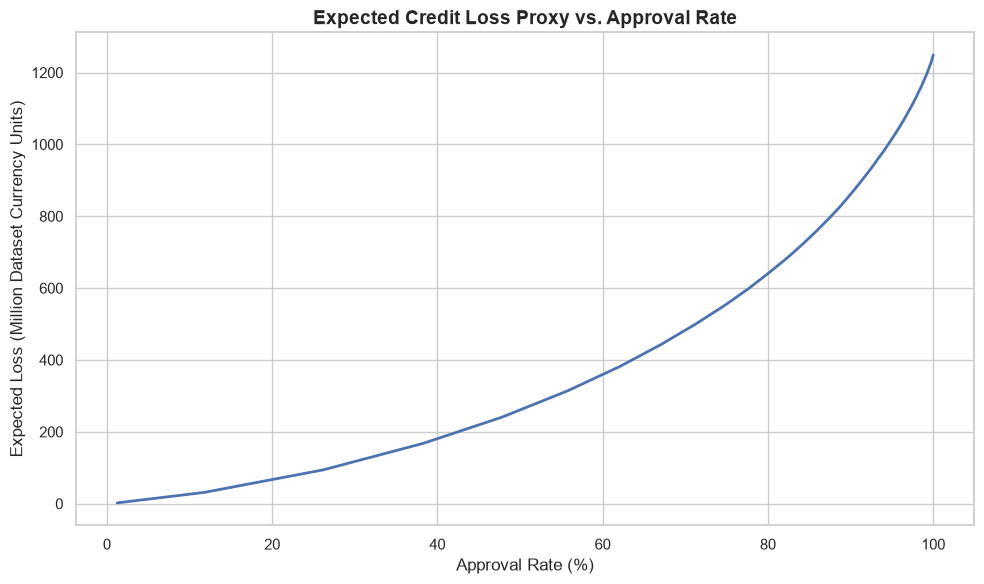

In [74]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    financial_df["Approval_Rate"] * 100,
    financial_df["Expected_Loss"] / 1e6,
    linewidth=2
)

ax.set_title(
    "Expected Credit Loss Proxy vs. Approval Rate",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Approval Rate (%)")
ax.set_ylabel("Expected Loss (Million Dataset Currency Units)")

plt.tight_layout()
plt.show()


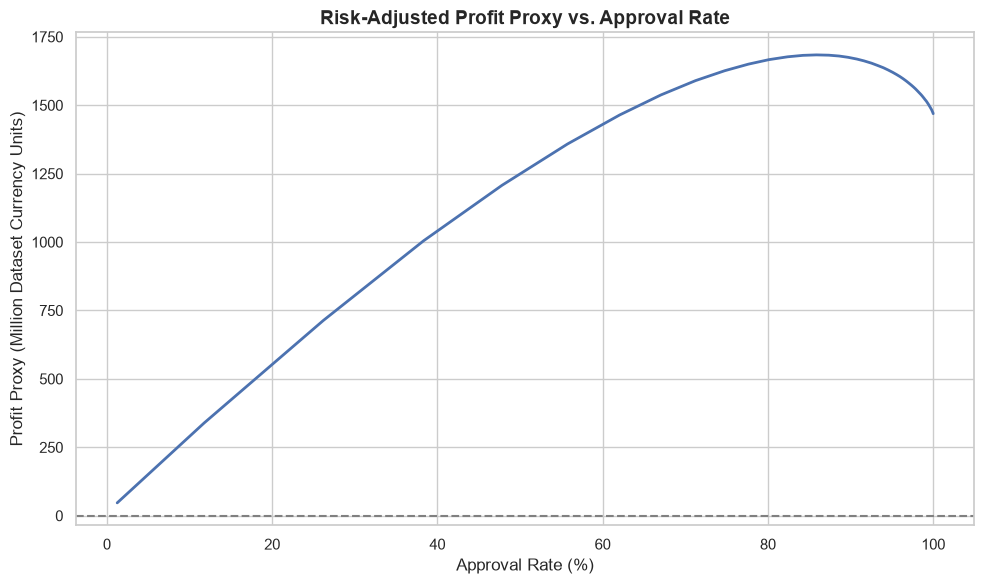

In [75]:

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    financial_df["Approval_Rate"] * 100,
    financial_df["Risk_Adjusted_Profit"] / 1e6,
    linewidth=2
)

ax.axhline(
    0,
    linestyle="--",
    color="gray"
)

ax.set_title(
    "Risk-Adjusted Profit Proxy vs. Approval Rate",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Approval Rate (%)")
ax.set_ylabel("Profit Proxy (Million Dataset Currency Units)")

plt.tight_layout()
plt.show()


In [76]:

profit_optimal_policy = financial_df.loc[
    financial_df["Risk_Adjusted_Profit"].idxmax()
].copy()

print("=== Profit-Maximizing Policy ===")

display(
    profit_optimal_policy.to_frame().T.round(4)
)


=== Profit-Maximizing Policy ===


,Threshold,Approved_Customers,Approval_Rate,Approved_Bad_Rate,Approved_Amount,Expected_Contribution,Expected_Loss,Risk_Adjusted_Profit,Profit_Margin
14,0.15,"52,811.00",0.86,0.05,"32,219,040,181.50","2,442,646,417.89","758,681,981.02","1,683,964,436.87",0.05


In [77]:

eligible_policies = financial_df[
    (financial_df["Approval_Rate"] >= MIN_APPROVAL_RATE)
    &
    (financial_df["Approved_Bad_Rate"] <= MAX_APPROVED_BAD_RATE)
].copy()

if eligible_policies.empty:

    constrained_policy = None

    print("No policy satisfies the business constraints.")

else:

    constrained_policy = eligible_policies.loc[
        eligible_policies["Risk_Adjusted_Profit"].idxmax()
    ].copy()

    print("=== Constrained Optimal Policy ===")

    display(
        constrained_policy.to_frame().T.round(4)
    )


=== Constrained Optimal Policy ===


,Threshold,Approved_Customers,Approval_Rate,Approved_Bad_Rate,Approved_Amount,Expected_Contribution,Expected_Loss,Risk_Adjusted_Profit,Profit_Margin
11,0.12,"49,276.00",0.80,0.05,"30,293,117,262.00","2,309,208,205.04","642,606,614.53","1,666,601,590.52",0.06



### 8.3 Financial Sensitivity Analysis

예상 신용손실은 부도확률뿐 아니라 부도 시 손실률(LGD)에 따라 크게 달라질 수 있다.

실제 금융기관에서는 담보 회수율, 고객 유형, 채권 회수 비용 및 경제 상황에 따라 손실률이 달라진다.

본 프로젝트에서는 LGD를 30%, 45%, 60%로 설정하여 금융 시나리오에 대한 민감도 분석을 수행한다.

이를 통해 특정 대출 승인 정책의 수익성이 손실률 가정에 얼마나 민감한지 평가한다.


In [78]:

lgd_scenarios = [0.30, 0.45, 0.60]

sensitivity_results = []

for lgd in lgd_scenarios:

    for threshold in thresholds:

        approved = risk_scores < threshold

        if approved.sum() == 0:
            continue

        pd_selected = risk_scores[approved]
        credit_selected = credit_amount[approved]

        expected_loss = np.sum(
            pd_selected * lgd * credit_selected
        )

        contribution = np.sum(
            (1 - pd_selected)
            * credit_selected
            * CONTRIBUTION_RATE
        )

        sensitivity_results.append({
            "LGD": lgd,
            "Threshold": round(threshold, 4),
            "Approval_Rate": approved.mean(),
            "Risk_Adjusted_Profit": (
                contribution - expected_loss
            )
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.head())


,LGD,Threshold,Approval_Rate,Risk_Adjusted_Profit
0,0.30,0.01,0.01,"47,556,392.52"
1,0.30,0.02,0.12,"349,430,771.96"
2,0.30,0.03,0.26,"744,653,916.49"
3,0.30,0.04,0.38,"1,060,729,097.52"
4,0.30,0.05,0.48,"1,287,471,873.29"


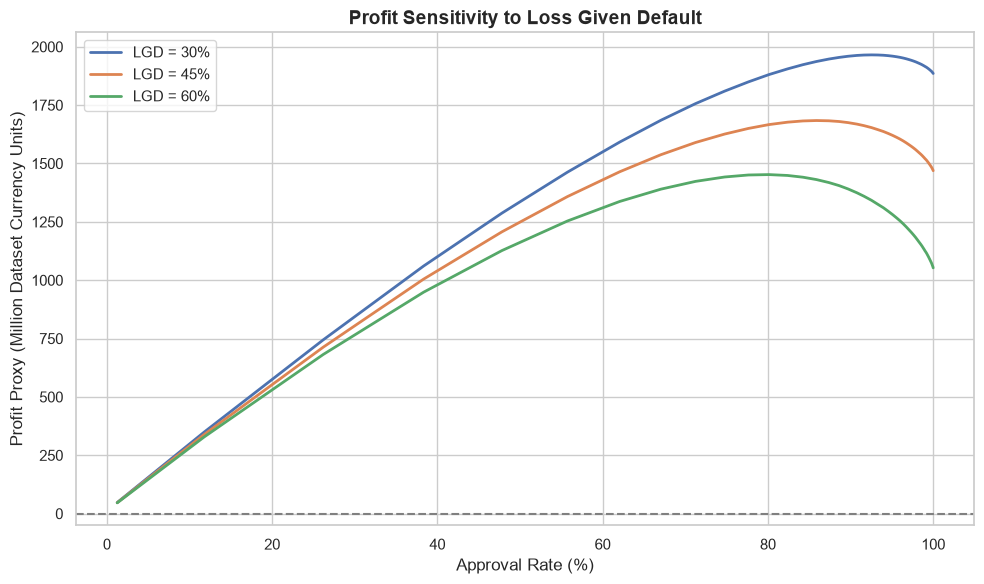

In [79]:

fig, ax = plt.subplots(figsize=(10, 6))

for lgd in lgd_scenarios:

    subset = sensitivity_df[
        sensitivity_df["LGD"] == lgd
    ]

    ax.plot(
        subset["Approval_Rate"] * 100,
        subset["Risk_Adjusted_Profit"] / 1e6,
        label=f"LGD = {lgd:.0%}",
        linewidth=2
    )

ax.axhline(
    0,
    linestyle="--",
    color="gray"
)

ax.set_title(
    "Profit Sensitivity to Loss Given Default",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Approval Rate (%)")
ax.set_ylabel("Profit Proxy (Million Dataset Currency Units)")

ax.legend()

plt.tight_layout()
plt.show()


In [80]:

comparison_rows = []

profit_row = profit_optimal_policy.to_dict()
profit_row["Policy"] = "Maximum Profit"
comparison_rows.append(profit_row)

if constrained_policy is not None:

    constrained_row = constrained_policy.to_dict()
    constrained_row["Policy"] = "Business Constrained"
    comparison_rows.append(constrained_row)

financial_policy_comparison = pd.DataFrame(
    comparison_rows
)

display(
    financial_policy_comparison[
        [
            "Policy",
            "Threshold",
            "Approval_Rate",
            "Approved_Bad_Rate",
            "Expected_Contribution",
            "Expected_Loss",
            "Risk_Adjusted_Profit",
            "Profit_Margin"
        ]
    ].round(4)
)


,Policy,Threshold,Approval_Rate,Approved_Bad_Rate,Expected_Contribution,Expected_Loss,Risk_Adjusted_Profit,Profit_Margin
0,Maximum Profit,0.15,0.86,0.05,"2,442,646,417.89","758,681,981.02","1,683,964,436.87",0.05
1,Business Constrained,0.12,0.80,0.05,"2,309,208,205.04","642,606,614.53","1,666,601,590.52",0.06



### 8.4 Financial Impact & Business Insights

본 단계에서는 신용위험 예측 모델의 확률 출력을 활용하여 가정 기반 예상 신용손실과 위험조정 수익을 시뮬레이션하였다.

#### Key Analysis

1. 모델 예측확률의 Calibration 검토
2. PD, LGD, EAD를 활용한 예상 신용손실 대용 지표 계산
3. 대출 승인율별 예상 영업기여액 및 손실 비교
4. 위험조정 수익 최대화 정책 도출
5. 비즈니스 제약조건을 고려한 정책 비교
6. LGD 변화에 따른 수익성 민감도 분석

#### Business Value

고객별 신용위험 예측 결과를 단순 분류 지표에 그치지 않고 금융기관의 대출 승인 전략 및 예상 손실 분석으로 확장하였다.

이를 통해 금융기관의 위험 허용 수준과 수익성 가정을 고려한 대출 심사 정책을 비교할 수 있는 분석 체계를 구축하였다.

#### Limitations

- 실제 금융기관의 확정 손실과 수익을 추정한 결과가 아니다.
- 모델의 상환 곤란 확률은 실제 부도확률과 다를 수 있다.
- LGD와 영업기여율은 가정한 값이다.
- 신청 대출금액을 실제 EAD의 대용 지표로 사용하였다.
- Validation 데이터에서 정책을 선택했기 때문에 최종 Test 평가가 필요하다.
- 실제 운영 적용 전에는 규제, 공정성 및 시간에 따른 모델 안정성 검증이 필요하다.

#### Next Step

최종 Test 데이터에서 선택한 모델과 승인 정책의 성능을 평가한다.

이후 데이터 분석 결과와 금융 시뮬레이션 결과를 종합하여 경영진을 위한 Business Recommendation을 작성한다.



## 9. Final Test Evaluation & Business Recommendations

### 9.1 Business Objective

본 단계에서는 Validation 데이터에서 선정한 신용위험 예측 모델과 대출 승인 정책을 독립적인 Test 데이터에 적용하여 일반화 성능을 평가한다.

모델 개발 및 정책 최적화 과정에서는 Training과 Validation 데이터만 사용하였으며, Test 데이터는 최종 평가를 위해 별도로 보존하였다.

### Key Evaluation Questions

1. 최종 모델은 새로운 고객 데이터에서도 신용위험을 효과적으로 구분하는가?
2. Validation에서 선정한 승인 정책이 Test 데이터에서도 목표 승인율과 위험률을 유지하는가?
3. 선정한 정책의 예상 신용손실과 위험조정 수익은 어느 정도인가?
4. 분석 결과를 바탕으로 금융기관에 어떤 대출 심사 전략을 제안할 수 있는가?

### Evaluation Principles

- 최종 Test 데이터를 이용한 모델 재선정 금지
- Test 결과를 보고 승인 Threshold 재조정 금지
- 모델 성능과 금융 비즈니스 성과를 구분하여 평가
- 가정 기반 시뮬레이션과 실제 금융성과를 명확히 구분


In [81]:

# STEP 8에서 선택한 금융 모델
final_model = financial_model

# 비즈니스 제약조건 충족 여부 확인
if constrained_policy is not None:

    final_policy_name = "Business Constrained"
    final_policy = constrained_policy.copy()

else:

    final_policy_name = "Profit Maximization (Fallback)"
    final_policy = profit_optimal_policy.copy()

final_threshold = float(final_policy["Threshold"])

print("=== FINAL MODEL & POLICY ===")
print("Model:", best_model_name)
print("Probability Method:", probability_method)
print("Policy:", final_policy_name)
print("Threshold:", final_threshold)

if constrained_policy is None:
    print(
        "\nWARNING: No policy satisfied the original "
        "business constraints. The fallback policy "
        "is evaluated separately."
    )


=== FINAL MODEL & POLICY ===
Model: LightGBM
Probability Method: Original
Policy: Business Constrained
Threshold: 0.12


In [82]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

# 독립 Test 데이터 예측
test_proba = final_model.predict_proba(X_test)[:, 1]

test_actual = y_test.to_numpy()

test_roc_auc = roc_auc_score(
    y_test,
    test_proba
)

test_pr_auc = average_precision_score(
    y_test,
    test_proba
)

test_brier = brier_score_loss(
    y_test,
    test_proba
)

final_model_metrics = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC (Average Precision)",
        "Brier Score"
    ],
    "Test Result": [
        test_roc_auc,
        test_pr_auc,
        test_brier
    ]
})

display(final_model_metrics.round(4))


,Metric,Test Result
0,ROC-AUC,0.76
1,PR-AUC (Average Precision),0.25
2,Brier Score,0.07


In [83]:

validation_metrics = {
    "ROC_AUC": roc_auc_score(
        y_val, financial_val_proba
    ),
    "PR_AUC": average_precision_score(
        y_val, financial_val_proba
    ),
    "Brier_Score": brier_score_loss(
        y_val, financial_val_proba
    )
}

generalization_df = pd.DataFrame({
    "Metric": [
        "ROC_AUC",
        "PR_AUC",
        "Brier_Score"
    ],
    "Validation": list(validation_metrics.values()),
    "Test": [
        test_roc_auc,
        test_pr_auc,
        test_brier
    ]
})

generalization_df["Difference"] = (
    generalization_df["Test"]
    - generalization_df["Validation"]
)

display(generalization_df.round(4))


,Metric,Validation,Test,Difference
0,ROC_AUC,0.76,0.76,0.00
1,PR_AUC,0.25,0.25,0.00
2,Brier_Score,0.07,0.07,-0.00



### 9.2 Final Lending Policy Evaluation

Validation 데이터에서 선택한 대출 승인 Threshold를 변경하지 않고 Test 데이터에 적용한다.

고객의 예측 상환 곤란 확률이 Threshold 미만이면 승인 후보로 분류한다.

다음 지표를 평가한다.

- Approval Rate
- Approved Bad Rate
- Bad Capture Rate
- Good Customer Rejection Rate
- Approved Credit Amount Share

이는 실제 대출 승인 결과가 아니라 과거 관측 데이터에 적용한 가상 정책 평가이다.


In [84]:

# 최종 승인 정책
test_approved = test_proba < final_threshold
test_rejected = ~test_approved

total_test = len(test_actual)

approved_count = test_approved.sum()

total_bad = (test_actual == 1).sum()
total_good = (test_actual == 0).sum()

approved_bad = (
    test_approved & (test_actual == 1)
).sum()

rejected_bad = (
    test_rejected & (test_actual == 1)
).sum()

rejected_good = (
    test_rejected & (test_actual == 0)
).sum()

test_approval_rate = approved_count / total_test

test_approved_bad_rate = (
    approved_bad / approved_count
    if approved_count > 0 else np.nan
)

test_bad_capture_rate = rejected_bad / total_bad

test_good_rejection_rate = rejected_good / total_good

test_policy_metrics = pd.DataFrame({
    "Metric": [
        "Approval Rate",
        "Approved Bad Rate",
        "Bad Capture Rate",
        "Good Customer Rejection Rate"
    ],
    "Test Result": [
        test_approval_rate,
        test_approved_bad_rate,
        test_bad_capture_rate,
        test_good_rejection_rate
    ]
})

display(test_policy_metrics.round(4))


,Metric,Test Result
0,Approval Rate,0.80
1,Approved Bad Rate,0.05
2,Bad Capture Rate,0.52
3,Good Customer Rejection Rate,0.17


In [85]:

test_credit = (
    X_test["AMT_CREDIT"]
    .to_numpy(dtype=float)
)

approved_pd = test_proba[test_approved]
approved_credit = test_credit[test_approved]

test_expected_loss = np.sum(
    approved_pd * LGD * approved_credit
)

test_expected_contribution = np.sum(
    (1 - approved_pd)
    * approved_credit
    * CONTRIBUTION_RATE
)

test_risk_adjusted_profit = (
    test_expected_contribution - test_expected_loss
)

test_approved_amount = approved_credit.sum()

test_profit_margin = (
    test_risk_adjusted_profit / test_approved_amount
    if test_approved_amount > 0 else np.nan
)

financial_impact_df = pd.DataFrame({
    "Metric": [
        "Approved Customers",
        "Approved Amount",
        "Expected Contribution",
        "Expected Credit Loss Proxy",
        "Risk-Adjusted Profit Proxy",
        "Profit Margin"
    ],
    "Value": [
        approved_count,
        test_approved_amount,
        test_expected_contribution,
        test_expected_loss,
        test_risk_adjusted_profit,
        test_profit_margin
    ]
})

display(financial_impact_df)


,Metric,Value
0,Approved Customers,"49,490.00"
1,Approved Amount,"30,513,419,001.00"
2,Expected Contribution,"2,326,600,444.58"
3,Expected Credit Loss Proxy,"643,911,049.66"
4,Risk-Adjusted Profit Proxy,"1,682,689,394.92"
5,Profit Margin,0.06


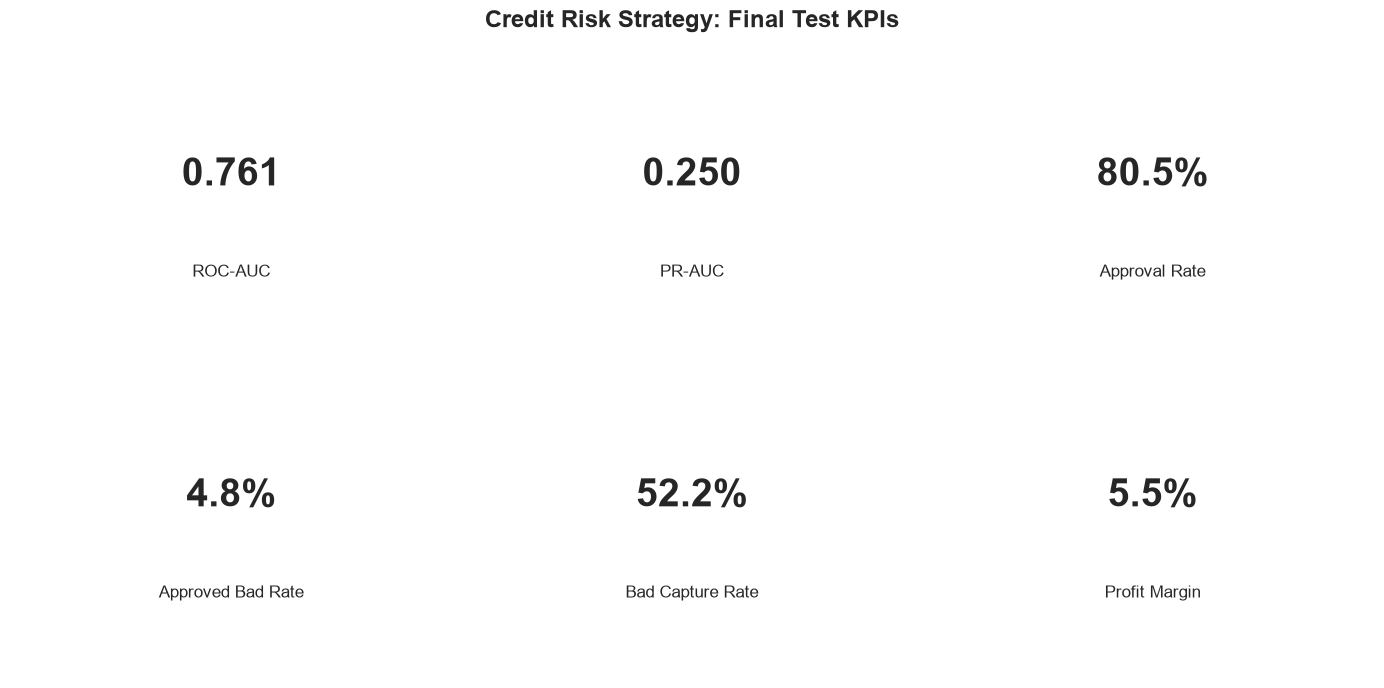

In [86]:

import matplotlib.pyplot as plt

kpi_names = [
    "ROC-AUC",
    "PR-AUC",
    "Approval Rate",
    "Approved Bad Rate",
    "Bad Capture Rate",
    "Profit Margin"
]

kpi_values = [
    test_roc_auc,
    test_pr_auc,
    test_approval_rate,
    test_approved_bad_rate,
    test_bad_capture_rate,
    test_profit_margin
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

for ax, name, value in zip(
    axes, kpi_names, kpi_values
):

    ax.axis("off")

    if name in ["ROC-AUC", "PR-AUC"]:
        formatted_value = f"{value:.3f}"
    else:
        formatted_value = f"{value:.1%}"

    ax.text(
        0.5, 0.60,
        formatted_value,
        ha="center",
        va="center",
        fontsize=28,
        fontweight="bold",
        transform=ax.transAxes
    )

    ax.text(
        0.5, 0.28,
        name,
        ha="center",
        va="center",
        fontsize=12,
        transform=ax.transAxes
    )

fig.suptitle(
    "Credit Risk Strategy: Final Test KPIs",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [87]:

print("=" * 65)
print("CREDIT RISK MODEL — BUSINESS RECOMMENDATION")
print("=" * 65)

print(f"\nSelected Model: {best_model_name}")
print(f"Probability Method: {probability_method}")
print(f"Selected Policy: {final_policy_name}")
print(f"Risk Threshold: {final_threshold:.2%}")

print("\n[Model Performance]")
print(f"ROC-AUC: {test_roc_auc:.4f}")
print(f"PR-AUC: {test_pr_auc:.4f}")
print(f"Brier Score: {test_brier:.4f}")

print("\n[Lending Strategy]")
print(f"Approval Rate: {test_approval_rate:.2%}")
print(f"Approved Bad Rate: {test_approved_bad_rate:.2%}")
print(f"Bad Capture Rate: {test_bad_capture_rate:.2%}")
print(f"Good Rejection Rate: {test_good_rejection_rate:.2%}")

print("\n[Financial Simulation]")
print(f"Expected Loss Proxy: {test_expected_loss:,.2f}")
print(f"Profit Proxy: {test_risk_adjusted_profit:,.2f}")
print(f"Profit Margin: {test_profit_margin:.2%}")

print("\n[Business Constraint Check]")
print(
    "Approval Target Met:",
    test_approval_rate >= MIN_APPROVAL_RATE
)
print(
    "Risk Target Met:",
    test_approved_bad_rate <= MAX_APPROVED_BAD_RATE
)

print("\nNote: Results are based on hypothetical financial assumptions.")


CREDIT RISK MODEL — BUSINESS RECOMMENDATION

Selected Model: LightGBM
Probability Method: Original
Selected Policy: Business Constrained
Risk Threshold: 12.00%

[Model Performance]
ROC-AUC: 0.7613
PR-AUC: 0.2498
Brier Score: 0.0676

[Lending Strategy]
Approval Rate: 80.47%
Approved Bad Rate: 4.79%
Bad Capture Rate: 52.23%
Good Rejection Rate: 16.66%

[Financial Simulation]
Expected Loss Proxy: 643,911,049.66
Profit Proxy: 1,682,689,394.92
Profit Margin: 5.51%

[Business Constraint Check]
Approval Target Met: True
Risk Target Met: True

Note: Results are based on hypothetical financial assumptions.



### 9.3 Executive Summary

#### Business Problem

금융기관은 신용위험에 따른 손실을 관리하는 동시에 정상 상환 고객의 대출 기회를 유지해야 한다.

본 프로젝트에서는 고객의 신용정보 및 과거 금융거래 이력을 활용하여 상환 곤란 위험을 예측하고, 모델 기반 대출 승인 전략을 분석하였다.

#### Analytical Approach

**1. Data Engineering**
- SQLite 기반 신용정보 데이터베이스 구축
- 고객 신청 정보 및 외부 신용 이력 통합
- SQL 집계를 활용한 고객별 신용정보 파생 변수 생성

**2. Exploratory Data Analysis**
- 소득 및 신청 대출금에 따른 위험 분석
- 기존 부채 및 과거 신용 이력 분석
- 고객 수 및 신청금액 기준 위험 노출 비교

**3. Predictive Modeling**
- Logistic Regression Baseline
- LightGBM 비교 모델
- ROC-AUC, PR-AUC 및 확률 보정 평가

**4. Business Optimization**
- 승인 Threshold별 정책 비교
- 위험 고객 차단율 및 정상 고객 거절률 분석
- 가정 기반 예상 신용손실 계산
- 위험조정 수익 및 LGD 민감도 분석

#### Final Results

다음 항목은 최종 Test 결과를 확인한 후 기록한다.

- Selected Model: [모델명]
- Test ROC-AUC: [실제 결과]
- Test PR-AUC: [실제 결과]
- Approval Rate: [실제 결과]
- Approved Bad Rate: [실제 결과]
- Expected Credit Loss Proxy: [실제 결과]
- Risk-Adjusted Profit Proxy: [실제 결과]

#### Business Recommendation

Validation 데이터에서 선정한 대출 승인 정책을 독립 Test 데이터에 적용하여 승인율, 신용위험 및 가정 기반 금융성과를 평가하였다.

실제 결과를 바탕으로 금융기관의 최소 승인율과 최대 위험 허용 수준을 만족하는지 검토하고, 승인 기회와 신용손실 사이의 균형을 고려한 정책을 제안한다.

#### Limitations

- 공개된 과거 관측 데이터를 기반으로 분석하였다.
- 실제 금융기관의 승인 이력 및 확정 손실 정보는 포함되지 않았다.
- 모델 예측확률을 실제 규제 목적 부도확률로 해석할 수 없다.
- LGD, EAD 및 영업기여율은 시나리오 가정에 기반한다.
- 시간에 따른 모델 성능 변화 및 공정성 검증은 추가 연구가 필요하다.

#### Conclusion

본 프로젝트는 신용위험 예측 모델을 금융기관의 대출 심사 의사결정 문제로 확장하였다.

단순한 예측 성능 비교를 넘어 승인율, 위험 고객 차단율, 예상 손실 및 수익성 간 Trade-off를 정량적으로 분석하는 의사결정 지원 프레임워크를 구축하였다.


In [88]:

from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# 모델 성능 비교
model_comparison.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

# 승인 정책 비교
financial_df.to_csv(
    output_dir / "financial_scenarios.csv",
    index=False
)

# 최종 Test KPI
final_model_metrics.to_csv(
    output_dir / "final_model_metrics.csv",
    index=False
)

test_policy_metrics.to_csv(
    output_dir / "final_policy_metrics.csv",
    index=False
)

financial_impact_df.to_csv(
    output_dir / "final_financial_impact.csv",
    index=False
)

print("Project results exported successfully!")


Project results exported successfully!



## 10. Portfolio Presentation & Executive Summary

### 10.1 Project Overview

**Project:** Credit Risk Modeling & Loan Approval Optimization

**Objective:** Develop a credit risk prediction framework and evaluate hypothetical lending policies by balancing approval opportunities, payment difficulty risk, and expected financial losses.

**Business Problem:** Financial institutions must manage credit risk while preserving lending opportunities for customers who are likely to repay.

**Analytical Approach:**

1. Build a customer-level Credit Risk Data Mart using SQLite.
2. Analyze financial capacity and historical credit exposure.
3. Compare Logistic Regression and LightGBM models.
4. Evaluate ROC-AUC, PR-AUC, and probability calibration.
5. Simulate lending strategies under hypothetical financial assumptions.
6. Evaluate the selected policy on an independent test dataset.

**Deliverable:** A reproducible credit risk modeling and decision-support framework.


In [89]:

executive_summary = pd.DataFrame({
    "Business KPI": [
        "Total Applications",
        "Selected Model",
        "Test ROC-AUC",
        "Test PR-AUC",
        "Test Brier Score",
        "Approval Rate",
        "Approved Bad Rate",
        "Bad Capture Rate",
        "Expected Loss Proxy",
        "Risk-Adjusted Profit Proxy"
    ],
    "Result": [
        f"{len(df_mart):,}",
        best_model_name,
        f"{test_roc_auc:.4f}",
        f"{test_pr_auc:.4f}",
        f"{test_brier:.4f}",
        f"{test_approval_rate:.2%}",
        f"{test_approved_bad_rate:.2%}",
        f"{test_bad_capture_rate:.2%}",
        f"{test_expected_loss:,.0f}",
        f"{test_risk_adjusted_profit:,.0f}"
    ]
})

display(executive_summary)


,Business KPI,Result
0,Total Applications,"307,511"
1,Selected Model,LightGBM
2,Test ROC-AUC,0.7613
3,Test PR-AUC,0.2498
4,Test Brier Score,0.0676
5,Approval Rate,80.47%
6,Approved Bad Rate,4.79%
7,Bad Capture Rate,52.23%
8,Expected Loss Proxy,"643,911,050"
9,Risk-Adjusted Profit Proxy,"1,682,689,395"


In [90]:

approval_target_met = (
    test_approval_rate >= MIN_APPROVAL_RATE
)

risk_target_met = (
    np.isfinite(test_approved_bad_rate)
    and test_approved_bad_rate <= MAX_APPROVED_BAD_RATE
)

print("=== BUSINESS RECOMMENDATION ===")

if approval_target_met and risk_target_met:
    print(
        "The selected policy satisfied both hypothetical "
        "business constraints on the test dataset."
    )
    print(
        "Recommendation: Consider further validation "
        "before any operational use."
    )
else:
    print(
        "The selected policy did not satisfy all "
        "hypothetical business constraints on the test dataset."
    )
    print(
        "Recommendation: Review model limitations and "
        "business feasibility before proposing deployment."
    )

print("\nFinancial Simulation")
print(f"Expected Loss Proxy: {test_expected_loss:,.0f}")
print(f"Risk-Adjusted Profit Proxy: {test_risk_adjusted_profit:,.0f}")

print(
    "\nNote: These figures are hypothetical scenario estimates, "
    "not realized financial outcomes."
)


=== BUSINESS RECOMMENDATION ===
The selected policy satisfied both hypothetical business constraints on the test dataset.
Recommendation: Consider further validation before any operational use.

Financial Simulation
Expected Loss Proxy: 643,911,050
Risk-Adjusted Profit Proxy: 1,682,689,395

Note: These figures are hypothetical scenario estimates, not realized financial outcomes.


In [91]:

from pathlib import Path
import numpy as np

# 결과 표시용 함수
def fmt_pct(value):
    return f"{value:.2%}" if np.isfinite(value) else "N/A"

def fmt_num(value):
    return f"{value:,.0f}" if np.isfinite(value) else "N/A"

approval_target_met = (
    test_approval_rate >= MIN_APPROVAL_RATE
)

risk_target_met = (
    np.isfinite(test_approved_bad_rate)
    and test_approved_bad_rate <= MAX_APPROVED_BAD_RATE
)

constraints_met = approval_target_met and risk_target_met

recommendation = (
    "The selected policy satisfied both hypothetical "
    "business constraints on the held-out test data. "
    "Further temporal, fairness, and operational validation "
    "is required before deployment."
    if constraints_met else
    "The selected policy did not satisfy all hypothetical "
    "business constraints on the held-out test data. "
    "Policy feasibility and model reliability require review."
)

readme = f"""# Credit Risk Modeling & Loan Approval Optimization

### 신용위험 예측 기반 대출 승인 전략 및 예상 신용손실 분석

**Tech Stack:** Python, SQL, SQLite, Pandas, Scikit-learn, LightGBM

---

## 1. Executive Summary

This project develops a credit risk modeling and
lending decision-support framework using the
Home Credit Default Risk dataset.

The objective is to evaluate how predictive risk scores
can support lending decisions while balancing credit
risk and loan approval opportunities.

### Key Results

| Metric | Result |
|---|---:|
| Total Applications | {len(df_mart):,} |
| Selected Model | {best_model_name} |
| Probability Method | {probability_method} |
| Test ROC-AUC | {test_roc_auc:.4f} |
| Test Average Precision | {test_pr_auc:.4f} |
| Test Brier Score | {test_brier:.4f} |
| Selected Risk Threshold | {final_threshold:.2%} |
| Test Approval Rate | {fmt_pct(test_approval_rate)} |
| Approved Bad Rate | {fmt_pct(test_approved_bad_rate)} |
| Bad Capture Rate | {fmt_pct(test_bad_capture_rate)} |

---

## 2. Business Problem

Financial institutions face a fundamental trade-off:

- Approving more loans can increase business opportunities.
- Approving high-risk borrowers can increase credit losses.
- Rejecting low-risk borrowers can reduce potential revenue.

### Project Objectives

1. Predict customer payment difficulty risk.
2. Identify relevant financial and credit-history features.
3. Compare statistical and machine learning models.
4. Evaluate lending policy thresholds.
5. Simulate hypothetical credit losses and risk-adjusted profit.

---

## 3. Data Engineering

**Dataset:** Home Credit Default Risk (Kaggle)

### Data Sources

- application_train.csv: Customer application information
- bureau.csv: External credit history

### Implementation

- Chunk-based CSV ingestion into SQLite
- Customer-level SQL aggregation
- LEFT JOIN with customer ID validation
- Credit history and debt exposure feature creation
- Duplicate prevention and data integrity checks

The resulting analytical dataset preserves one
observation per application.

---

## 4. Exploratory Data Analysis

Business-oriented EDA examines:

- Income levels and payment difficulty rates
- Loan-to-income ratios
- Historical credit records
- Reported outstanding debt
- Requested credit exposure

The analysis identifies associations rather than
establishing causal relationships.

---

## 5. Predictive Modeling

### Models

**Logistic Regression**
- Interpretable baseline
- Median imputation
- Standard scaling

**LightGBM**
- Gradient boosting model
- Nonlinear relationships
- Credit risk prediction

### Evaluation

- ROC-AUC
- Average Precision
- Brier Score
- Probability Calibration

Training, validation, and test data are separated
to reduce data leakage and support independent evaluation.

---

## 6. Lending Policy Optimization

Customers with predicted risk below the selected
threshold are treated as hypothetical approval candidates.

### Final Policy

| KPI | Test Result |
|---|---:|
| Policy | {final_policy_name} |
| Threshold | {final_threshold:.2%} |
| Approval Rate | {fmt_pct(test_approval_rate)} |
| Approved Bad Rate | {fmt_pct(test_approved_bad_rate)} |
| Bad Capture Rate | {fmt_pct(test_bad_capture_rate)} |
| Good Rejection Rate | {fmt_pct(test_good_rejection_rate)} |

### Hypothetical Policy Constraints

- Minimum Approval Rate: {MIN_APPROVAL_RATE:.0%}
- Maximum Approved Bad Rate: {MAX_APPROVED_BAD_RATE:.0%}
- Both Constraints Satisfied on Test: {constraints_met}

---

## 7. Financial Impact Simulation

The financial simulation uses:

Expected Loss Proxy = PD Proxy × LGD × EAD Proxy

Assumptions:

- LGD: {LGD:.0%}
- Contribution Rate: {CONTRIBUTION_RATE:.0%}
- EAD Proxy: Requested loan amount

### Simulated Financial Results

| Financial Metric | Value |
|---|---:|
| Approved Amount | {fmt_num(test_approved_amount)} |
| Expected Contribution | {fmt_num(test_expected_contribution)} |
| Expected Loss Proxy | {fmt_num(test_expected_loss)} |
| Risk-Adjusted Profit Proxy | {fmt_num(test_risk_adjusted_profit)} |
| Profit Margin | {fmt_pct(test_profit_margin)} |

**Important:** These values are hypothetical simulation
results, not realized bank profits or accounting ECL.

---

## 8. Business Recommendation

{recommendation}

### Decision-Support Value

The framework compares lending strategies using
approval rates, observed payment difficulty rates,
predicted losses, and hypothetical profitability.

---

## 9. Limitations

- Payment difficulty is used as a proxy for default.
- Actual LGD and EAD are not available.
- Financial contribution assumptions are hypothetical.
- Random train/test splitting does not validate future performance.
- Historical applicant data may not represent future borrowers.
- Real-world deployment requires fairness, regulatory,
  and out-of-time validation.

---

## 10. Future Improvements

- Out-of-time model validation
- Model fairness and stability analysis
- SHAP-based model interpretation
- More realistic pricing and loss modeling
- Extended credit history aggregation

---

## Dataset

[Home Credit Default Risk — Kaggle](https://www.kaggle.com/competitions/home-credit-default-risk)

This is an independent educational portfolio project.
"""

Path("README.md").write_text(
    readme,
    encoding="utf-8"
)

print("README.md successfully generated!")


README.md successfully generated!


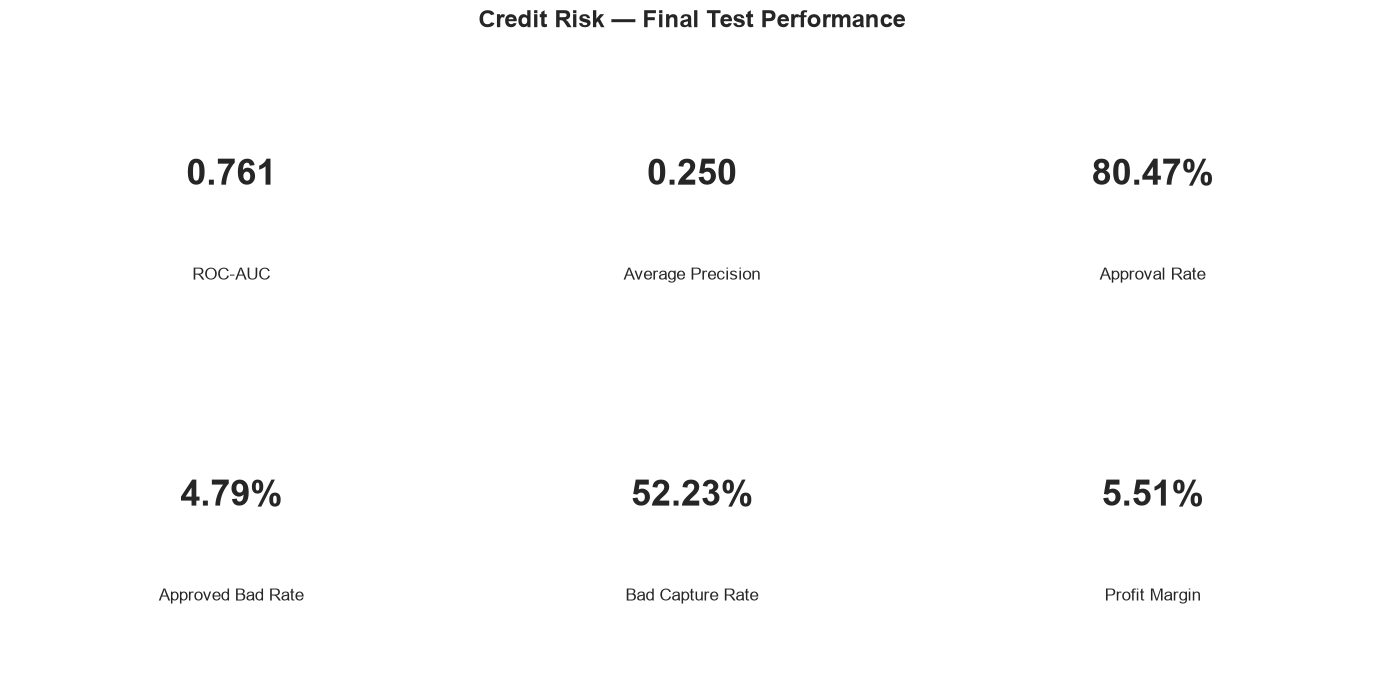

Dashboard saved successfully!


In [92]:

from pathlib import Path
import matplotlib.pyplot as plt

fig_dir = Path("figures")
fig_dir.mkdir(exist_ok=True)

kpis = [
    ("ROC-AUC", f"{test_roc_auc:.3f}"),
    ("Average Precision", f"{test_pr_auc:.3f}"),
    ("Approval Rate", fmt_pct(test_approval_rate)),
    ("Approved Bad Rate", fmt_pct(test_approved_bad_rate)),
    ("Bad Capture Rate", fmt_pct(test_bad_capture_rate)),
    ("Profit Margin", fmt_pct(test_profit_margin))
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for ax, (name, value) in zip(axes.flat, kpis):
    ax.axis("off")

    ax.text(
        0.5, 0.60,
        value,
        ha="center",
        va="center",
        fontsize=26,
        fontweight="bold",
        transform=ax.transAxes
    )

    ax.text(
        0.5, 0.27,
        name,
        ha="center",
        va="center",
        fontsize=12,
        transform=ax.transAxes
    )

fig.suptitle(
    "Credit Risk — Final Test Performance",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    fig_dir / "executive_dashboard.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Dashboard saved successfully!")



![Credit Risk Executive Dashboard](figures/executive_dashboard.png)



![Credit Risk Executive Dashboard](figures/executive_dashboard.png)


In [93]:

requirements = """pandas
numpy
matplotlib
seaborn
scikit-learn
lightgbm
tabulate
jupyter
"""

Path("requirements.txt").write_text(
    requirements,
    encoding="utf-8"
)

print("requirements.txt created!")


requirements.txt created!


In [94]:

gitignore = """# Raw data
*.csv
!outputs/*.csv

# Local database
*.db
*.sqlite

# Python
__pycache__/
*.pyc
.venv/

# Jupyter
.ipynb_checkpoints/

# System
.DS_Store
"""

Path(".gitignore").write_text(
    gitignore,
    encoding="utf-8"
)

print(".gitignore created!")


.gitignore created!


In [95]:

from pathlib import Path
import numpy as np

# 결과 파일 존재 확인
required_files = [
    "README.md",
    "requirements.txt",
    ".gitignore",
    "figures/executive_dashboard.png",
    "outputs/model_comparison.csv",
    "outputs/final_model_metrics.csv",
    "outputs/final_policy_metrics.csv",
    "outputs/final_financial_impact.csv"
]

missing_files = [
    path for path in required_files
    if not Path(path).exists()
]

assert not missing_files, (
    f"Missing files: {missing_files}"
)

# 최종 모델 평가 검증
assert np.isfinite(test_proba).all()
assert len(test_proba) == len(y_test)
assert np.all((test_proba >= 0) & (test_proba <= 1))

# 정책 기준 검증
assert 0 <= final_threshold <= 1

print("All Portfolio Quality Checks Passed!")
print("Ready for GitHub presentation!")


All Portfolio Quality Checks Passed!
Ready for GitHub presentation!
